# Week 7: Advanced Model

============================================================

IDX Exchange — Data Science Internship

Week 7: Advanced Models

Author: Zachary Blehm

============================================================

Summary:

Part 1:

The data set is a combination of the week 3 and week 6 pipelines. Imputation is based on aggregates computed over the full warm-up + training set (6 + 18 = 24 months). The zip level and knn aggregate calculations are based on an expanding window, while the zip price trend uses a 6 month moving window.

The feature set is also a combination of the week 3 and week 6 features sets, and uses all of the original (week 3) features, plus the additional features created in week 6.

The choice of this data set is based on the best overall performance of any dataset previously evaluated.

Best results for the XGBoost model were obtain using a learning rate of 0.015, maximum tree depth of 4 and 3000 trees. These parameter resulted in the following metrics: r-squared: 0.9126, Mean Absolute Error (MAE): $134,501 and Median Average Percent Error (MdAPE): 7.38%.

Part 2:

Looking ahead to week 9, we explore a subset of features that would be used for the Simple Prediction App and retune the XGBoost model on this subset.



In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import shap
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import ParameterGrid
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Training data is 18 months total (used +6 months for aggregate warm-up)
# Validation is 202603, Test is 202604

df_train = pd.read_csv("train_v3_18mo_6mo_mw_large_feature_set.csv")
df_val = pd.read_csv("val_v3_18mo_6mo_mw_large_feature_set.csv")
df_test = pd.read_csv("test_v3_18mo_6mo_mw_large_feature_set.csv")

In [3]:
def plot_train_vs_val_metrics(results):
    """
    Plot train vs validation metrics for each run in a ParameterGrid search.

    Parameters:
    - results: list of dicts returned by train_rf_model()
    """

    df = pd.DataFrame(results)

    # Create readable labels from parameter dicts
    df["label"] = df["params"].apply(
        lambda p: ", ".join(f"{k}={v}" for k, v in p.items()))

    metrics = [
        ("Train R^2", "Val R^2", "R^2 Score"),
        ("Train MAE", "Val MAE", "MAE"),
        ("Train MdAPE", "Val MdAPE", "MdAPE")
    ]

    plt.figure(figsize=(18, 20))

    for i, (train_col, val_col, title) in enumerate(metrics, 1):
        plt.subplot(3, 1, i)

        x = range(len(df))

        plt.plot(x, df[train_col], marker="o", label="Train", linewidth=2)
        plt.plot(x, df[val_col], marker="s", label="Validation", linewidth=2)

        plt.title(f"{title} — Train vs Validation")
        plt.xticks(x, df["label"], rotation=45, ha="right")
        plt.ylabel(title)
        plt.grid(True)
        plt.legend()

    plt.tight_layout()
    plt.show()

In [4]:
def train_xgboost_model(df_train, df_eval, param_grid, seed=42):
    """
    Train and evaluate XGBoost regression models over a parameter grid.

    Parameters:
    - df_train: Training data
    - df_eval: Validation data
    - param_grid: dict of parameter lists (depth, learning_rate, n_estimators)
    - seed: random_state for reproducibility

    Returns:
        results: list of dicts containing metrics for each parameter combination
    """

    results = []

    y_train = df_train["ClosePrice"]
    X_train = df_train.drop(columns=["ClosePrice"])

    y_eval = df_eval["ClosePrice"]
    X_eval = df_eval.drop(columns=["ClosePrice"])

    # Loop through each parameter combination
    for params in ParameterGrid(param_grid):

        model = XGBRegressor(
            random_state=seed,
            objective="reg:squarederror",
            **params
        )

        model.fit(X_train, y_train)

        # Predictions
        y_pred_train = model.predict(X_train)
        y_pred_val = model.predict(X_eval)

        # Metrics
        train_r2 = r2_score(y_train, y_pred_train)
        val_r2 = r2_score(y_eval, y_pred_val)

        train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
        val_rmse = np.sqrt(mean_squared_error(y_eval, y_pred_val))

        train_mae = mean_absolute_error(y_train, y_pred_train)
        val_mae = mean_absolute_error(y_eval, y_pred_val)

        train_mdape = np.median(np.abs((y_train - y_pred_train) / y_train)) * 100
        val_mdape = np.median(np.abs((y_eval - y_pred_val) / y_eval)) * 100

        entry = {
            "params": params,
            "Train R^2": train_r2,
            "Val R^2": val_r2,
            "Train RMSE": train_rmse,
            "Val RMSE": val_rmse,
            "Train MAE": train_mae,
            "Val MAE": val_mae,
            "Train MdAPE": train_mdape,
            "Val MdAPE": val_mdape
        }

        results.append(entry)
        print(entry)

    return results


# Part 1

{'params': {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}, 'Train R^2': 0.8922130854916923, 'Val R^2': 0.891851863841324, 'Train RMSE': np.float64(285118.0189967455), 'Val RMSE': np.float64(289026.81296005665), 'Train MAE': 150161.58877442655, 'Val MAE': 150932.81523205873, 'Train MdAPE': np.float64(8.274524678484532), 'Val MdAPE': np.float64(8.179108231707318)}
{'params': {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}, 'Train R^2': 0.9075155844664144, 'Val R^2': 0.9039787834427846, 'Train RMSE': np.float64(264104.5741503963), 'Val RMSE': np.float64(272340.49123361584), 'Train MAE': 139789.04385674617, 'Val MAE': 142015.1806812829, 'Train MdAPE': np.float64(7.78342984627069), 'Val MdAPE': np.float64(7.709408602150537)}
{'params': {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500}, 'Train R^2': 0.9134741070753938, 'Val R^2': 0.9077272254713746, 'Train RMSE': np.float64(255455.16601675813), 'Val RMSE': np.float64(266971.8089647665), 'Train MAE': 1358

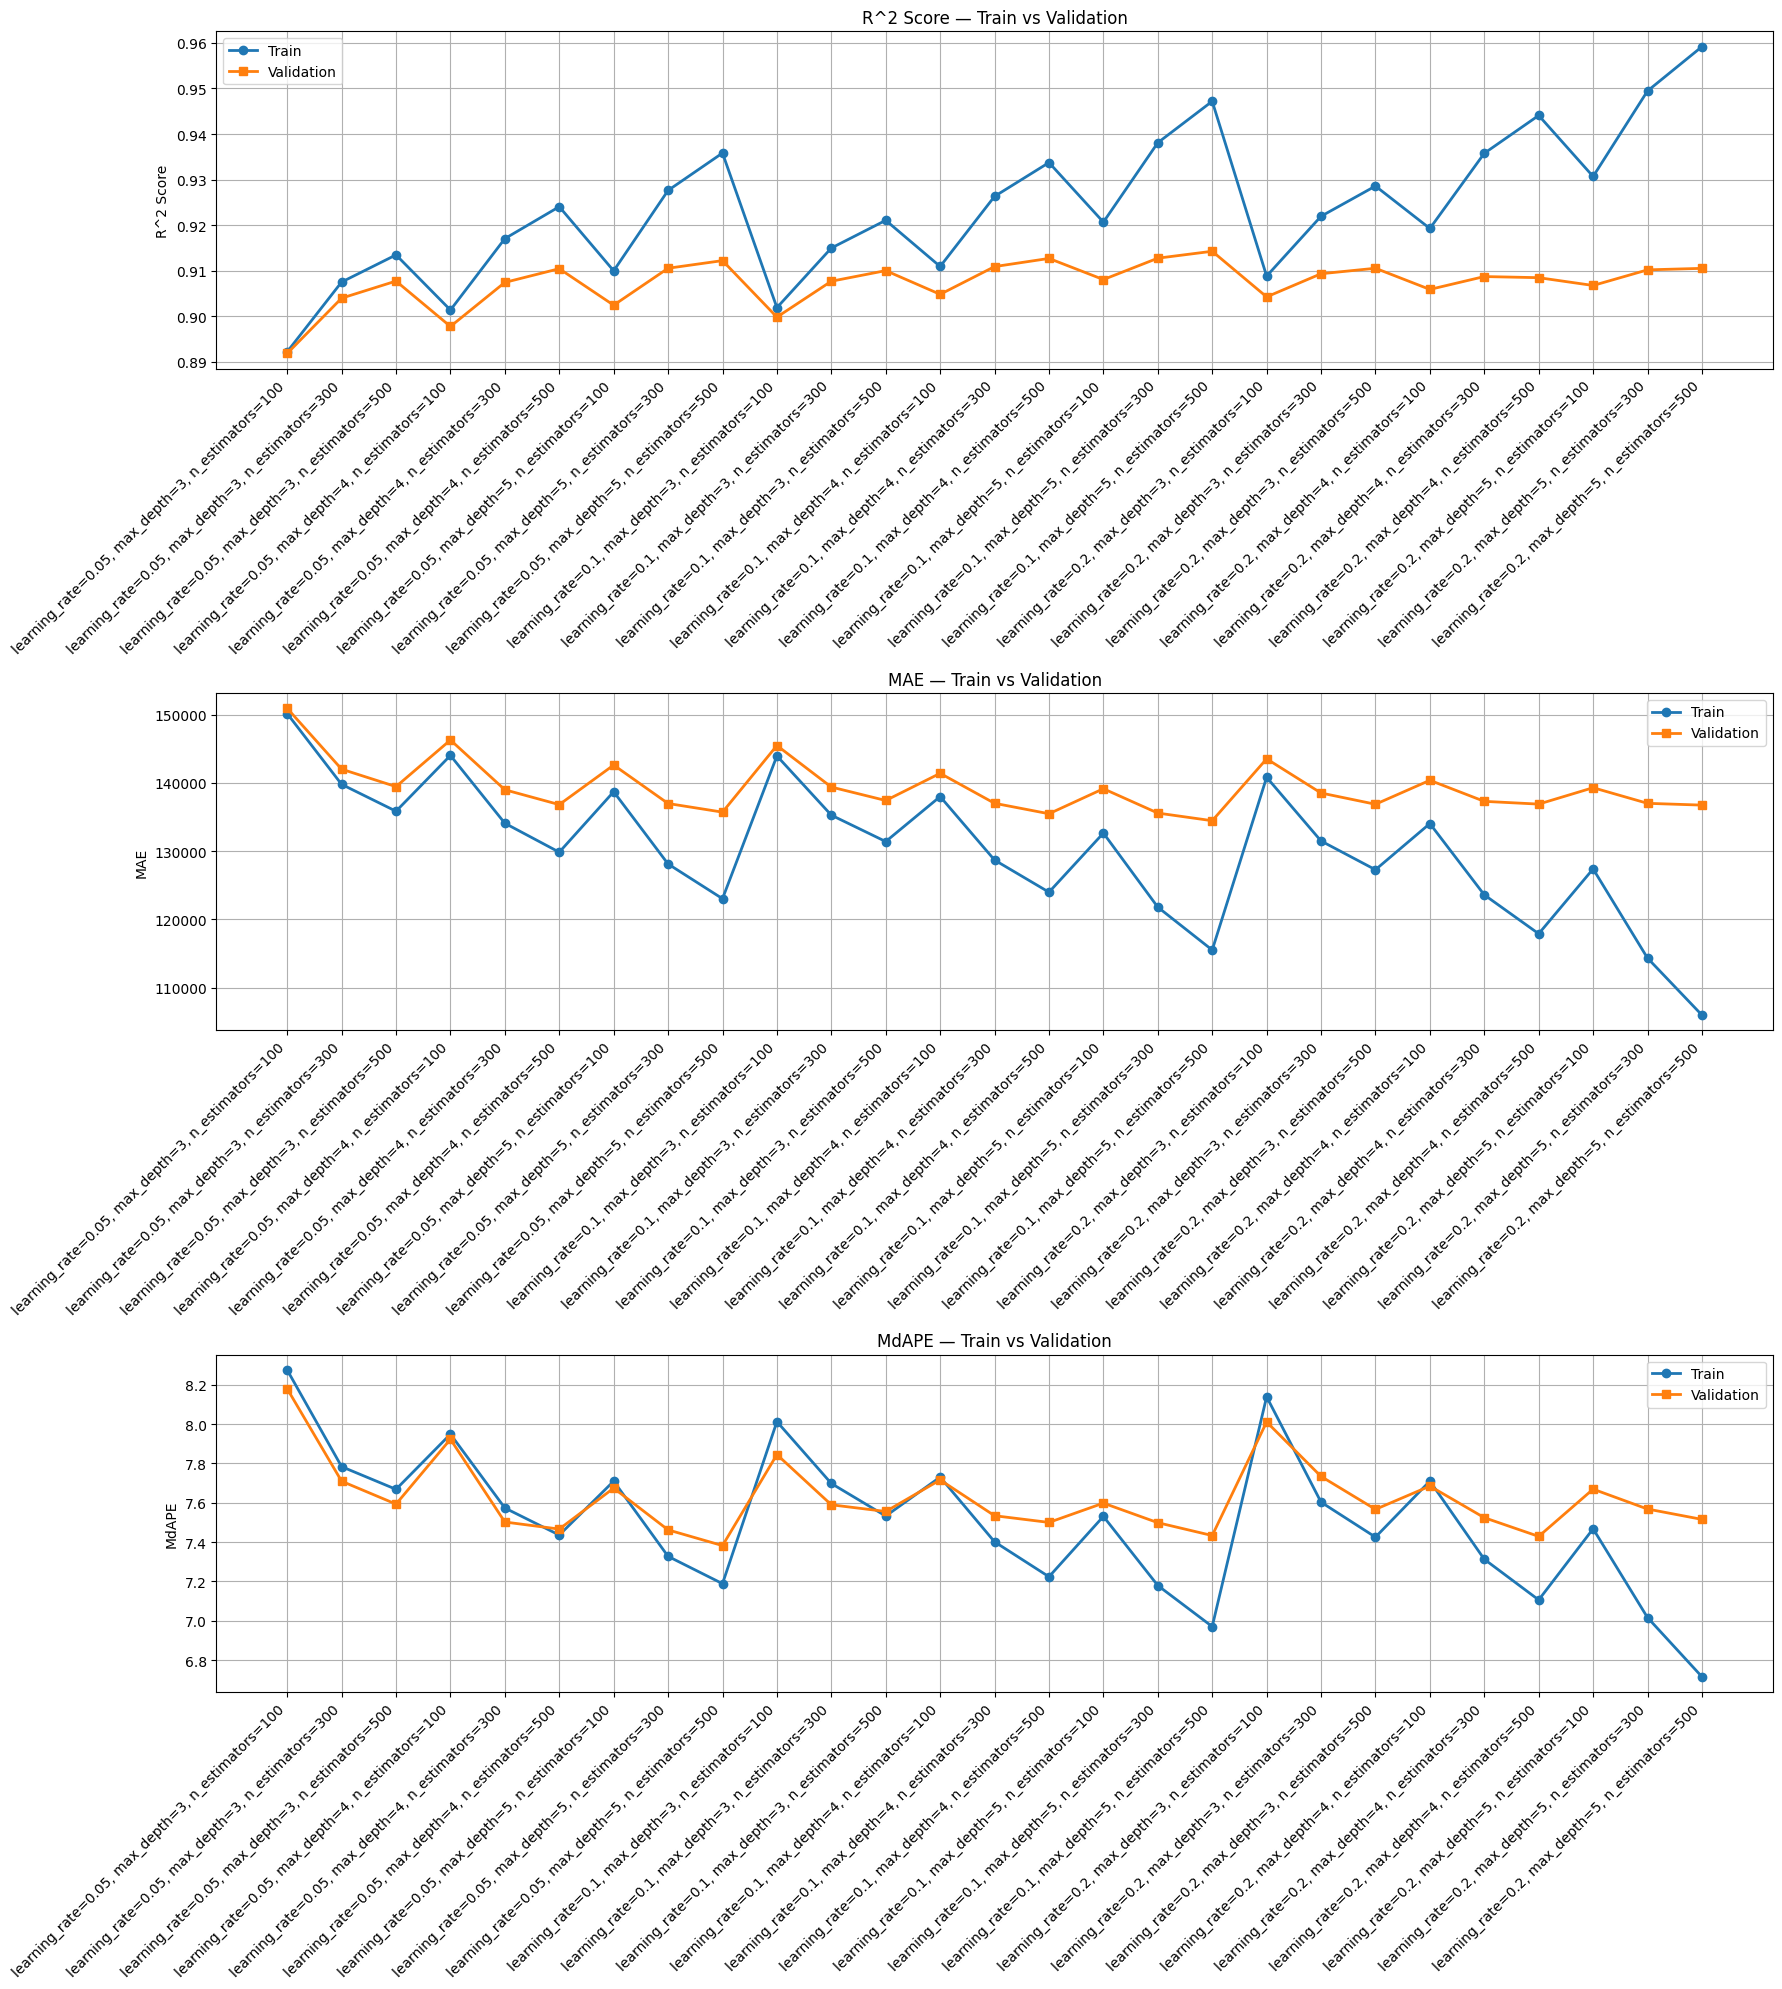

In [ ]:
xgb_params = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [100, 300, 500]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 300}, 'Train R^2': 0.8782056939644183, 'Val R^2': 0.8773422920376555, 'Train RMSE': np.float64(303078.5057911176), 'Val RMSE': np.float64(307805.25990781776), 'Train MAE': 160918.89519397897, 'Val MAE': 161653.65971517964, 'Train MdAPE': np.float64(9.536654759558532), 'Val MdAPE': np.float64(9.303784615384615)}
{'params': {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500}, 'Train R^2': 0.8924700710336932, 'Val R^2': 0.8924064562645482, 'Train RMSE': np.float64(284777.9269993922), 'Val RMSE': np.float64(288284.7839590156), 'Train MAE': 149908.55822329083, 'Val MAE': 150539.64444086544, 'Train MdAPE': np.float64(8.263514419082602), 'Val MdAPE': np.float64(8.254473995271868)}
{'params': {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 700}, 'Train R^2': 0.8979199600814717, 'Val R^2': 0.8972485460046564, 'Train RMSE': np.float64(277467.4612184164), 'Val RMSE': np.float64(281723.1933658812), 'Train MAE': 146

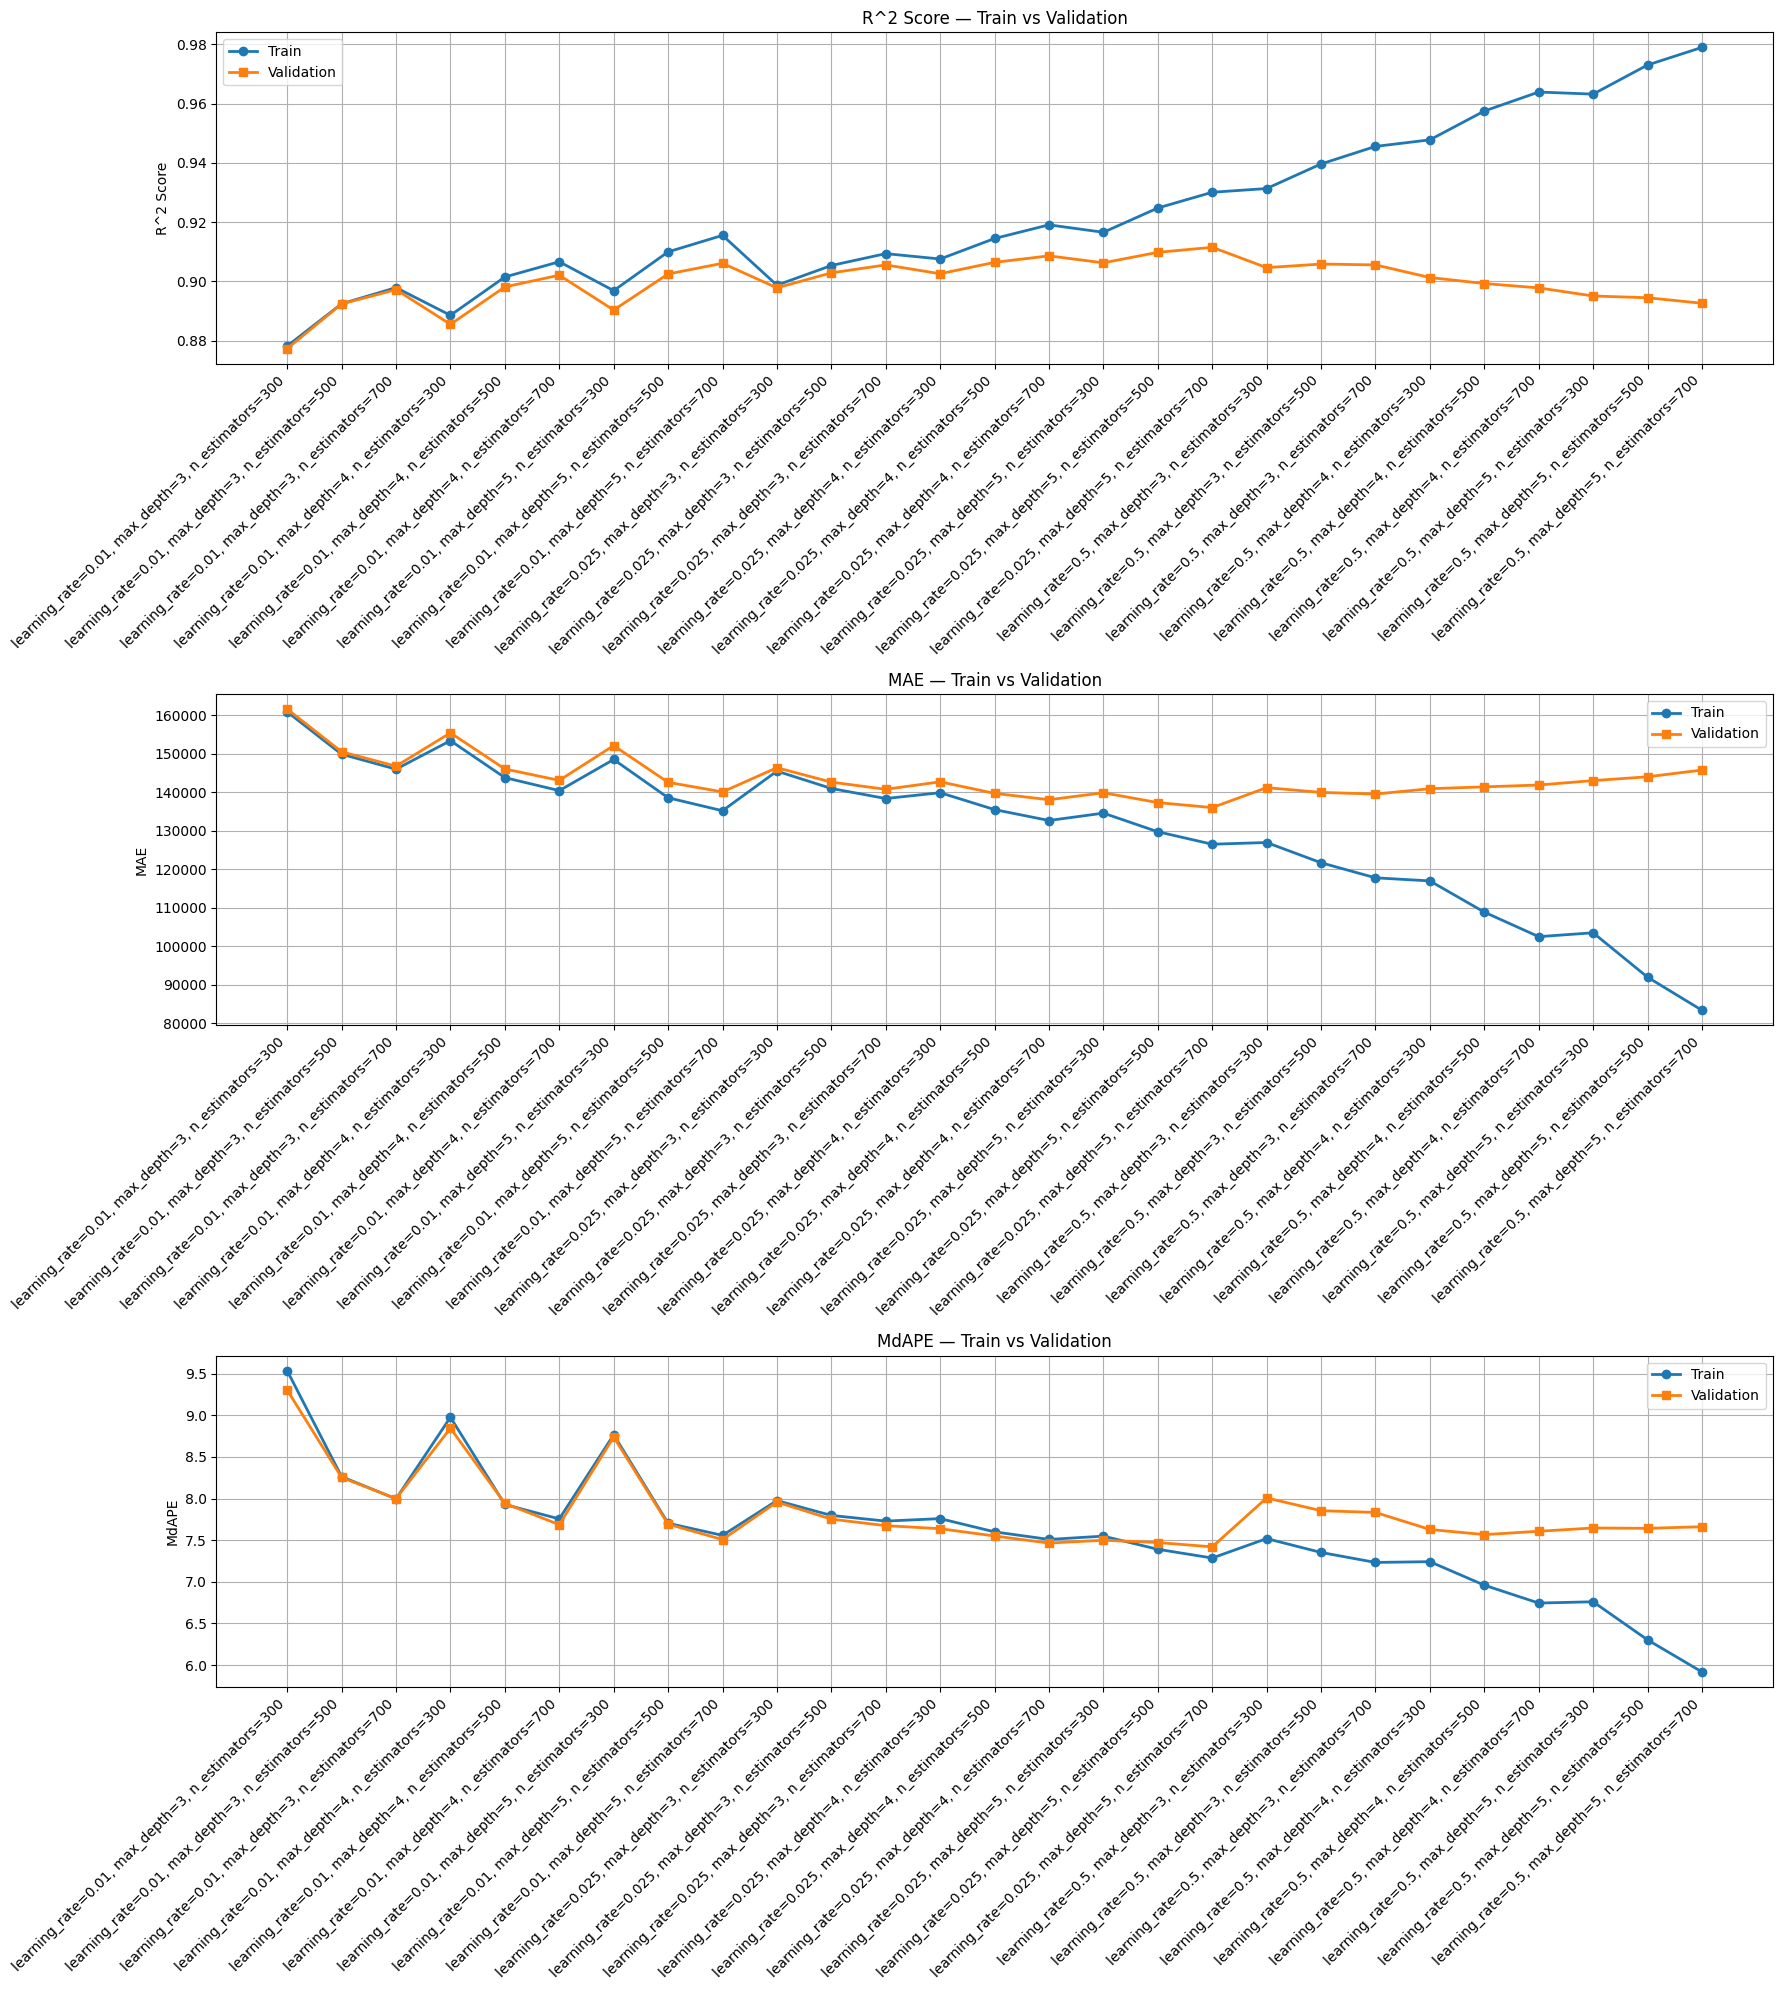

In [ ]:
xgb_params = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.025, 0.5],
    'n_estimators': [300, 500, 700]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.001, 'max_depth': 3, 'n_estimators': 700}, 'Train R^2': 0.6207681687460711, 'Val R^2': 0.6120452563544357, 'Train RMSE': np.float64(534803.2483359225), 'Val RMSE': np.float64(547418.0933898336), 'Train MAE': 339521.7845910534, 'Val MAE': 346782.9613184631, 'Train MdAPE': np.float64(26.66297275641026), 'Val MdAPE': np.float64(26.892593537414967)}
{'params': {'learning_rate': 0.001, 'max_depth': 3, 'n_estimators': 1000}, 'Train R^2': 0.7224712725933133, 'Val R^2': 0.7144676401174768, 'Train RMSE': np.float64(457504.76004172314), 'Val RMSE': np.float64(469630.48654825974), 'Train MAE': 279298.00104238116, 'Val MAE': 285316.8468188325, 'Train MdAPE': np.float64(21.496420522217132), 'Val MdAPE': np.float64(21.438919031719532)}
{'params': {'learning_rate': 0.001, 'max_depth': 3, 'n_estimators': 1300}, 'Train R^2': 0.7826979323270545, 'Val R^2': 0.7755996545784614, 'Train RMSE': np.float64(404830.82564041123), 'Val RMSE': np.float64(416332.5581385038), 'Train MA

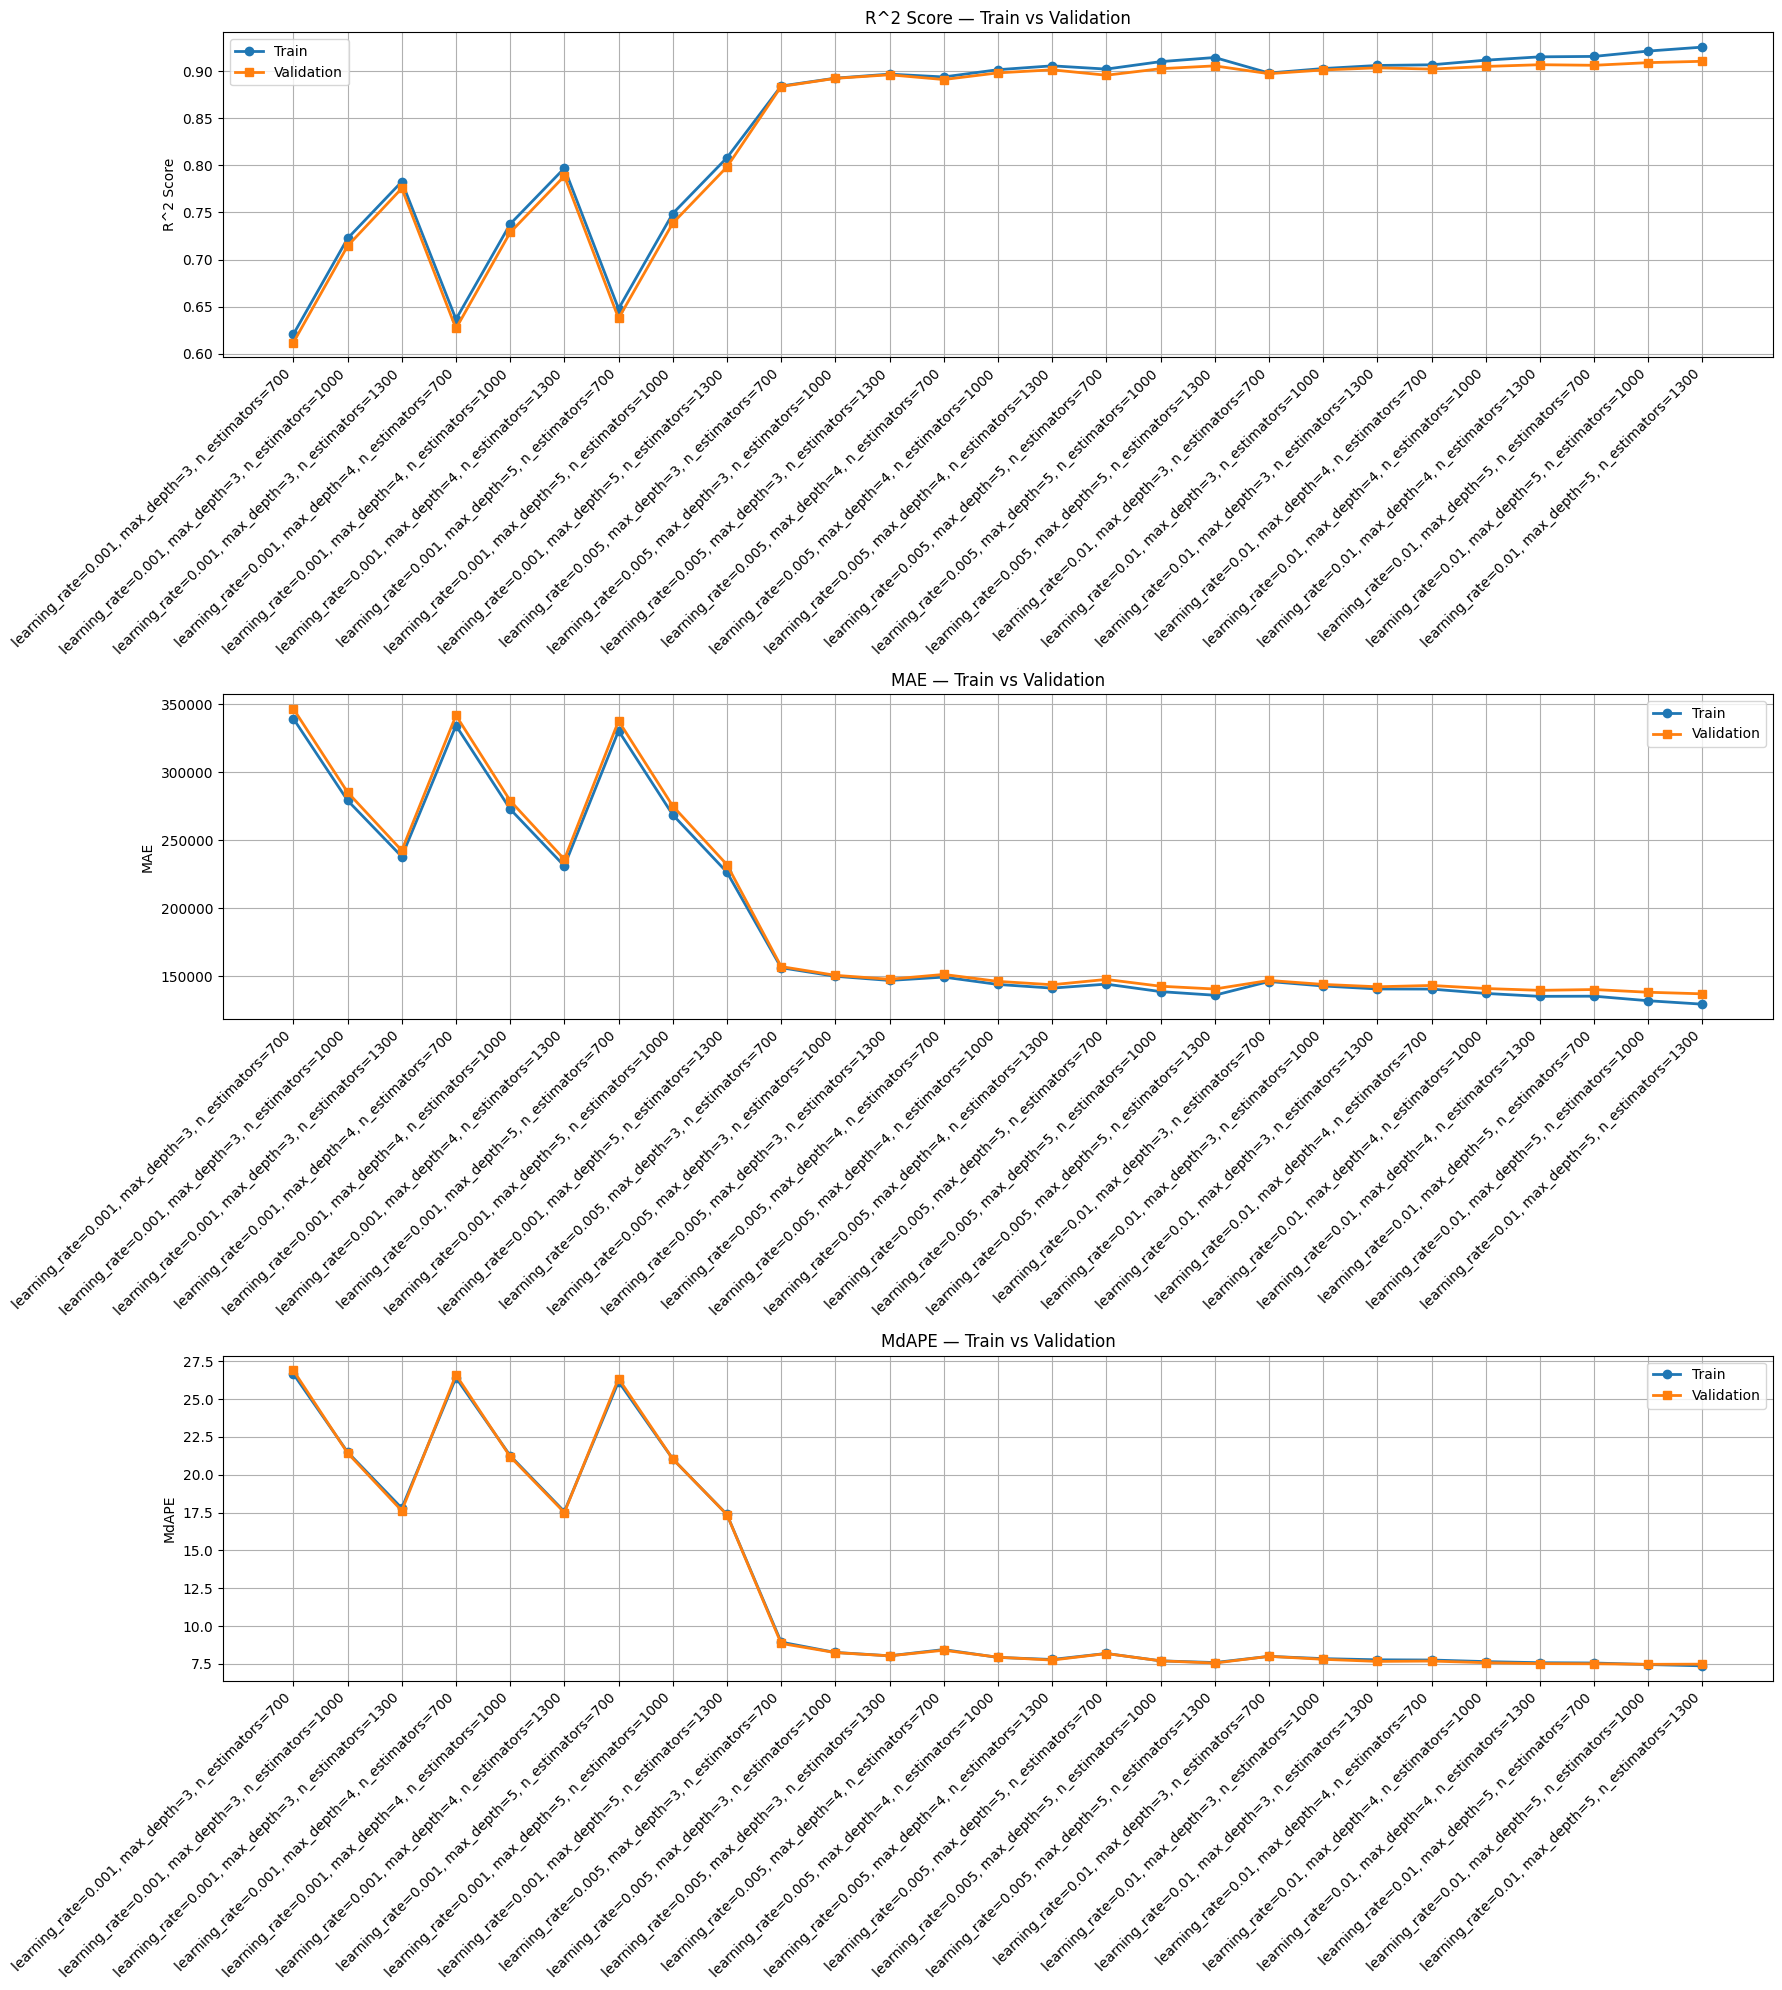

In [ ]:
xgb_params = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.001, 0.005, 0.01],
    'n_estimators': [700, 1000, 1300]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.005, 'max_depth': 4, 'n_estimators': 1300}, 'Train R^2': 0.9055628969448525, 'Val R^2': 0.9013506954333966, 'Train RMSE': np.float64(266878.1220604606), 'Val RMSE': np.float64(276042.294381535), 'Train MAE': 141158.6682020933, 'Val MAE': 143644.28689722452, 'Train MdAPE': np.float64(7.790721842105263), 'Val MdAPE': np.float64(7.7508313106796125)}
{'params': {'learning_rate': 0.005, 'max_depth': 4, 'n_estimators': 1500}, 'Train R^2': 0.9075957400888206, 'Val R^2': 0.9026565530407671, 'Train RMSE': np.float64(263990.1005104506), 'Val RMSE': np.float64(274209.17037465953), 'Train MAE': 139876.4960095827, 'Val MAE': 142658.62276473167, 'Train MdAPE': np.float64(7.745708686440677), 'Val MdAPE': np.float64(7.653291666666667)}
{'params': {'learning_rate': 0.005, 'max_depth': 4, 'n_estimators': 1800}, 'Train R^2': 0.9100816729433999, 'Val R^2': 0.9040756022825834, 'Train RMSE': np.float64(260414.85477758967), 'Val RMSE': np.float64(272203.1552292923), 'Train MAE'

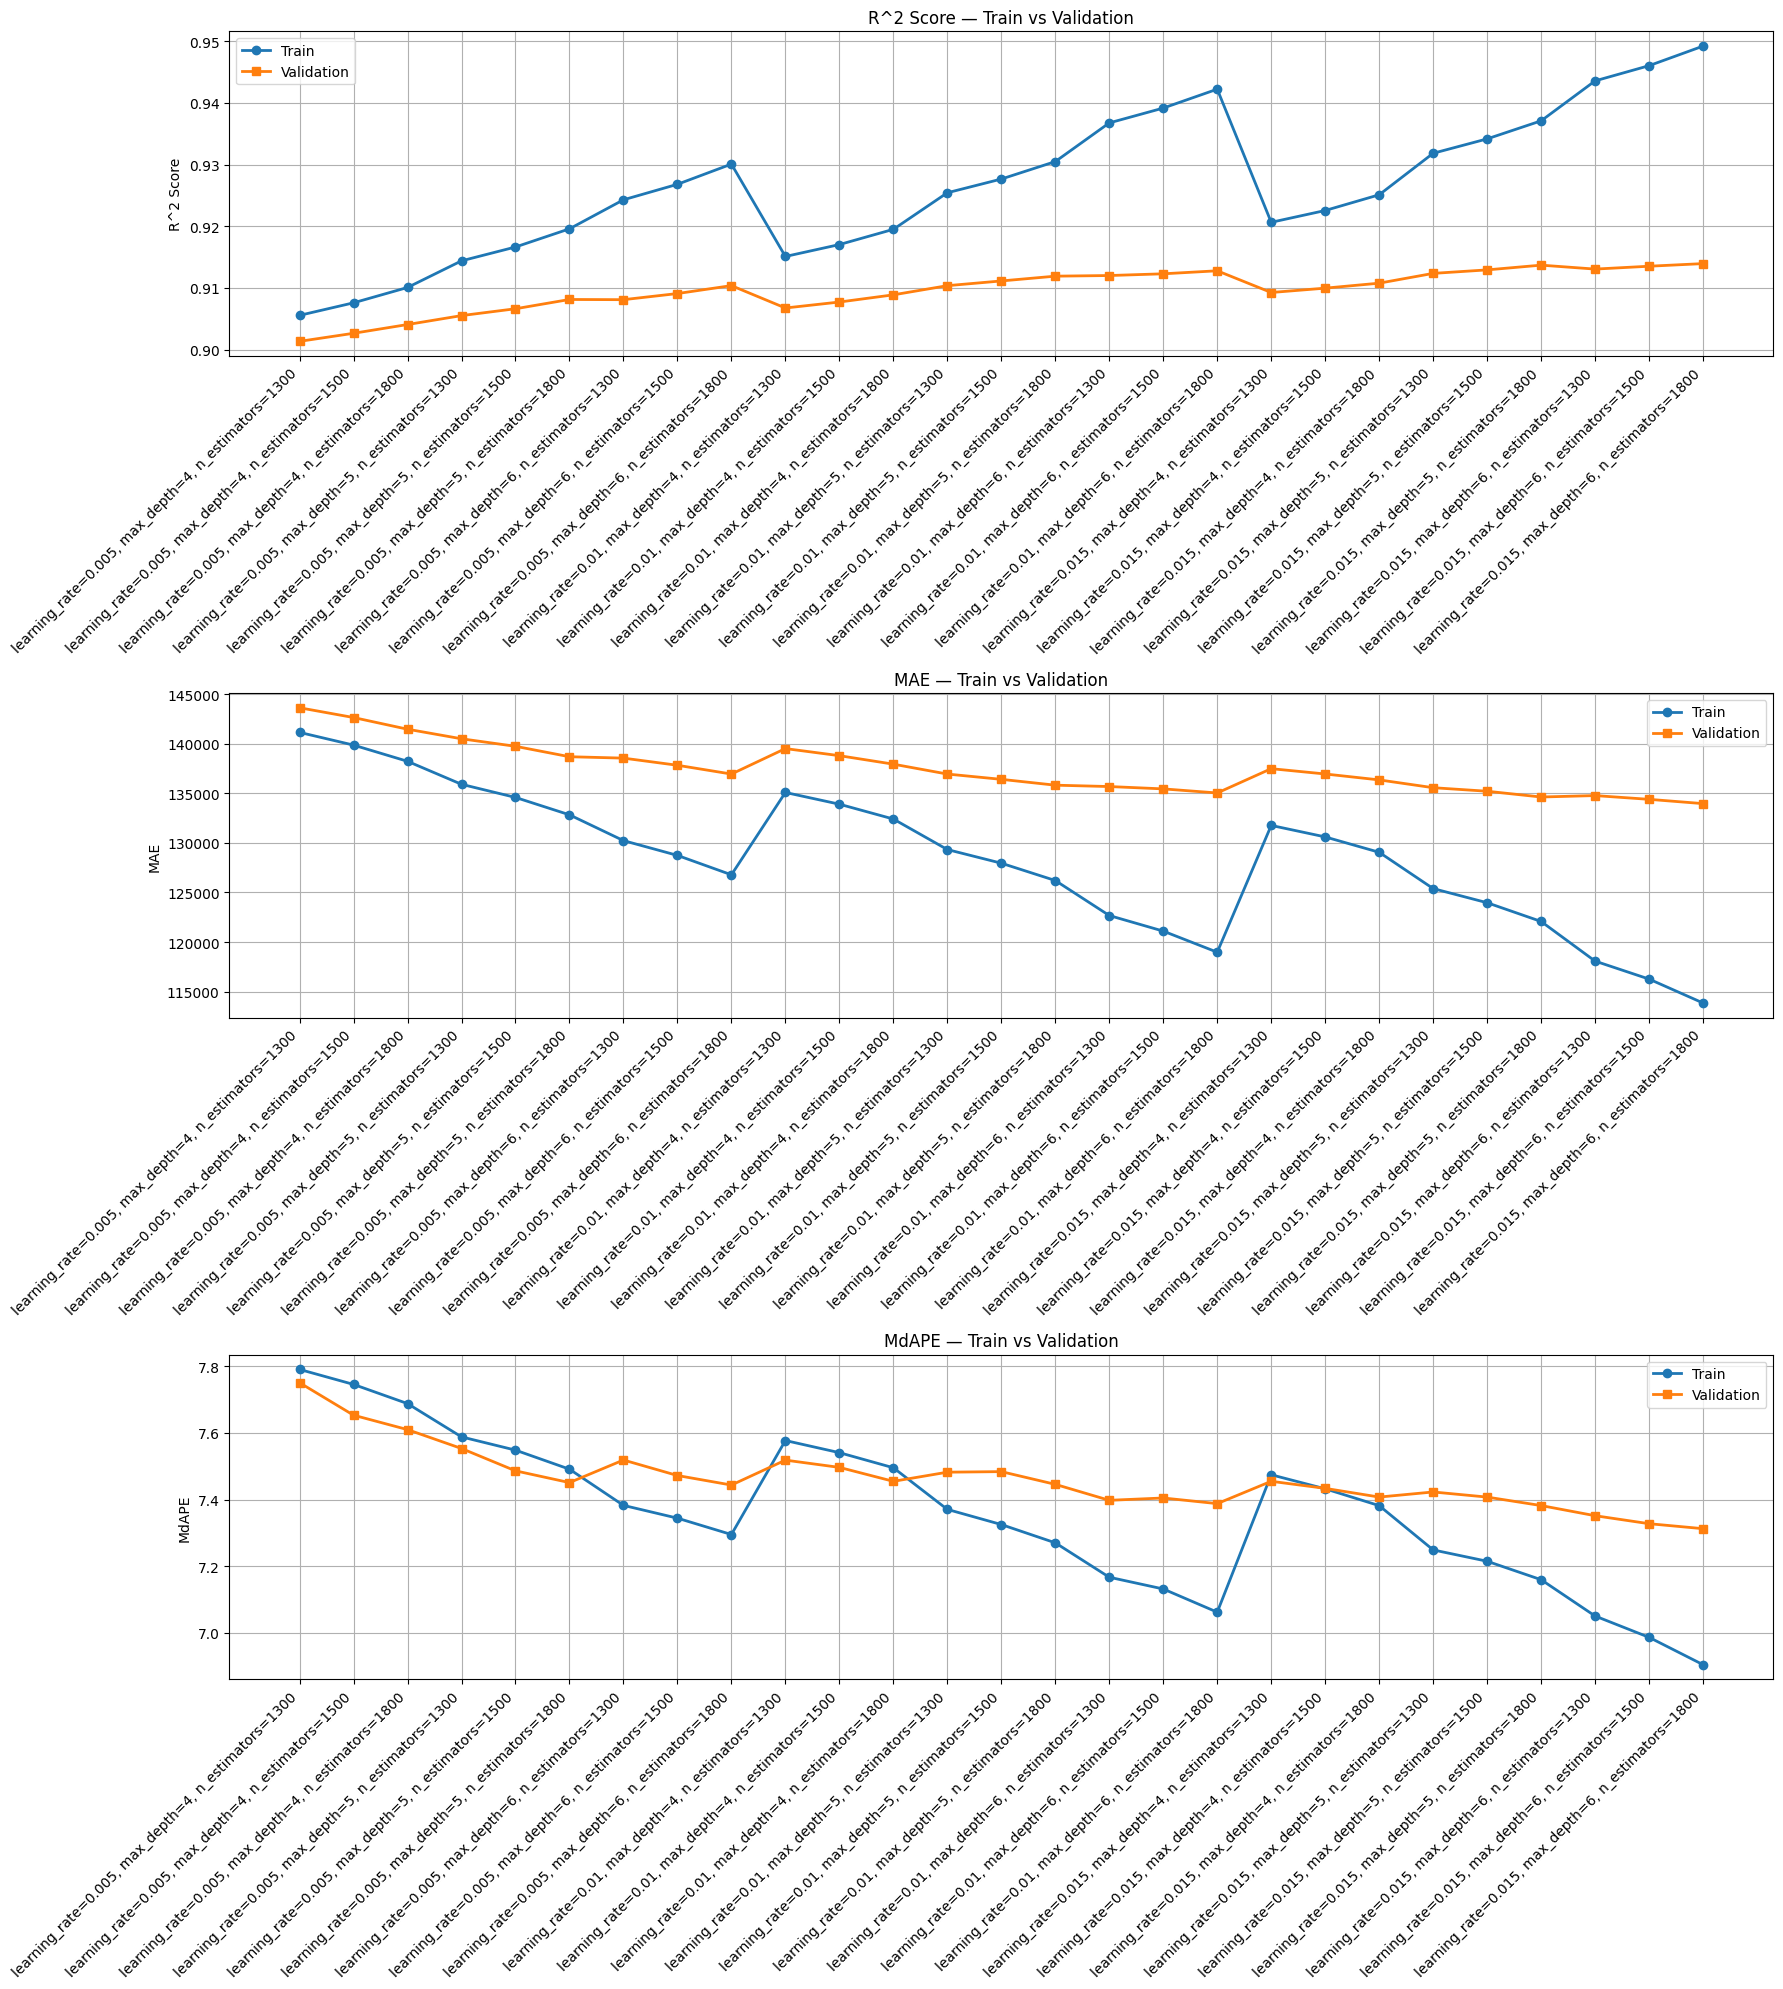

In [ ]:
xgb_params = {
    'max_depth': [4, 5, 6],
    'learning_rate': [0.005, 0.01, 0.015 ],
    'n_estimators': [1300, 1500, 1800]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 1500}, 'Train R^2': 0.8885982601974813, 'Val R^2': 0.88942374837505, 'Train RMSE': np.float64(289859.56196869956), 'Val RMSE': np.float64(292253.38255964994), 'Train MAE': 151984.29940687283, 'Val MAE': 152365.4678741803, 'Train MdAPE': np.float64(8.356380533199195), 'Val MdAPE': np.float64(8.396149999999999)}
{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 2000}, 'Train R^2': 0.8929411536577614, 'Val R^2': 0.8935858956797056, 'Train RMSE': np.float64(284153.44418156357), 'Val RMSE': np.float64(286700.34228890715), 'Train MAE': 148789.36343889876, 'Val MAE': 149574.29917267017, 'Train MdAPE': np.float64(8.14149325046779), 'Val MdAPE': np.float64(8.221185185185185)}
{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 2500}, 'Train R^2': 0.8957961003260597, 'Val R^2': 0.8963618293581046, 'Train RMSE': np.float64(280339.07169442327), 'Val RMSE': np.float64(282936.17869942257), 'Train MA

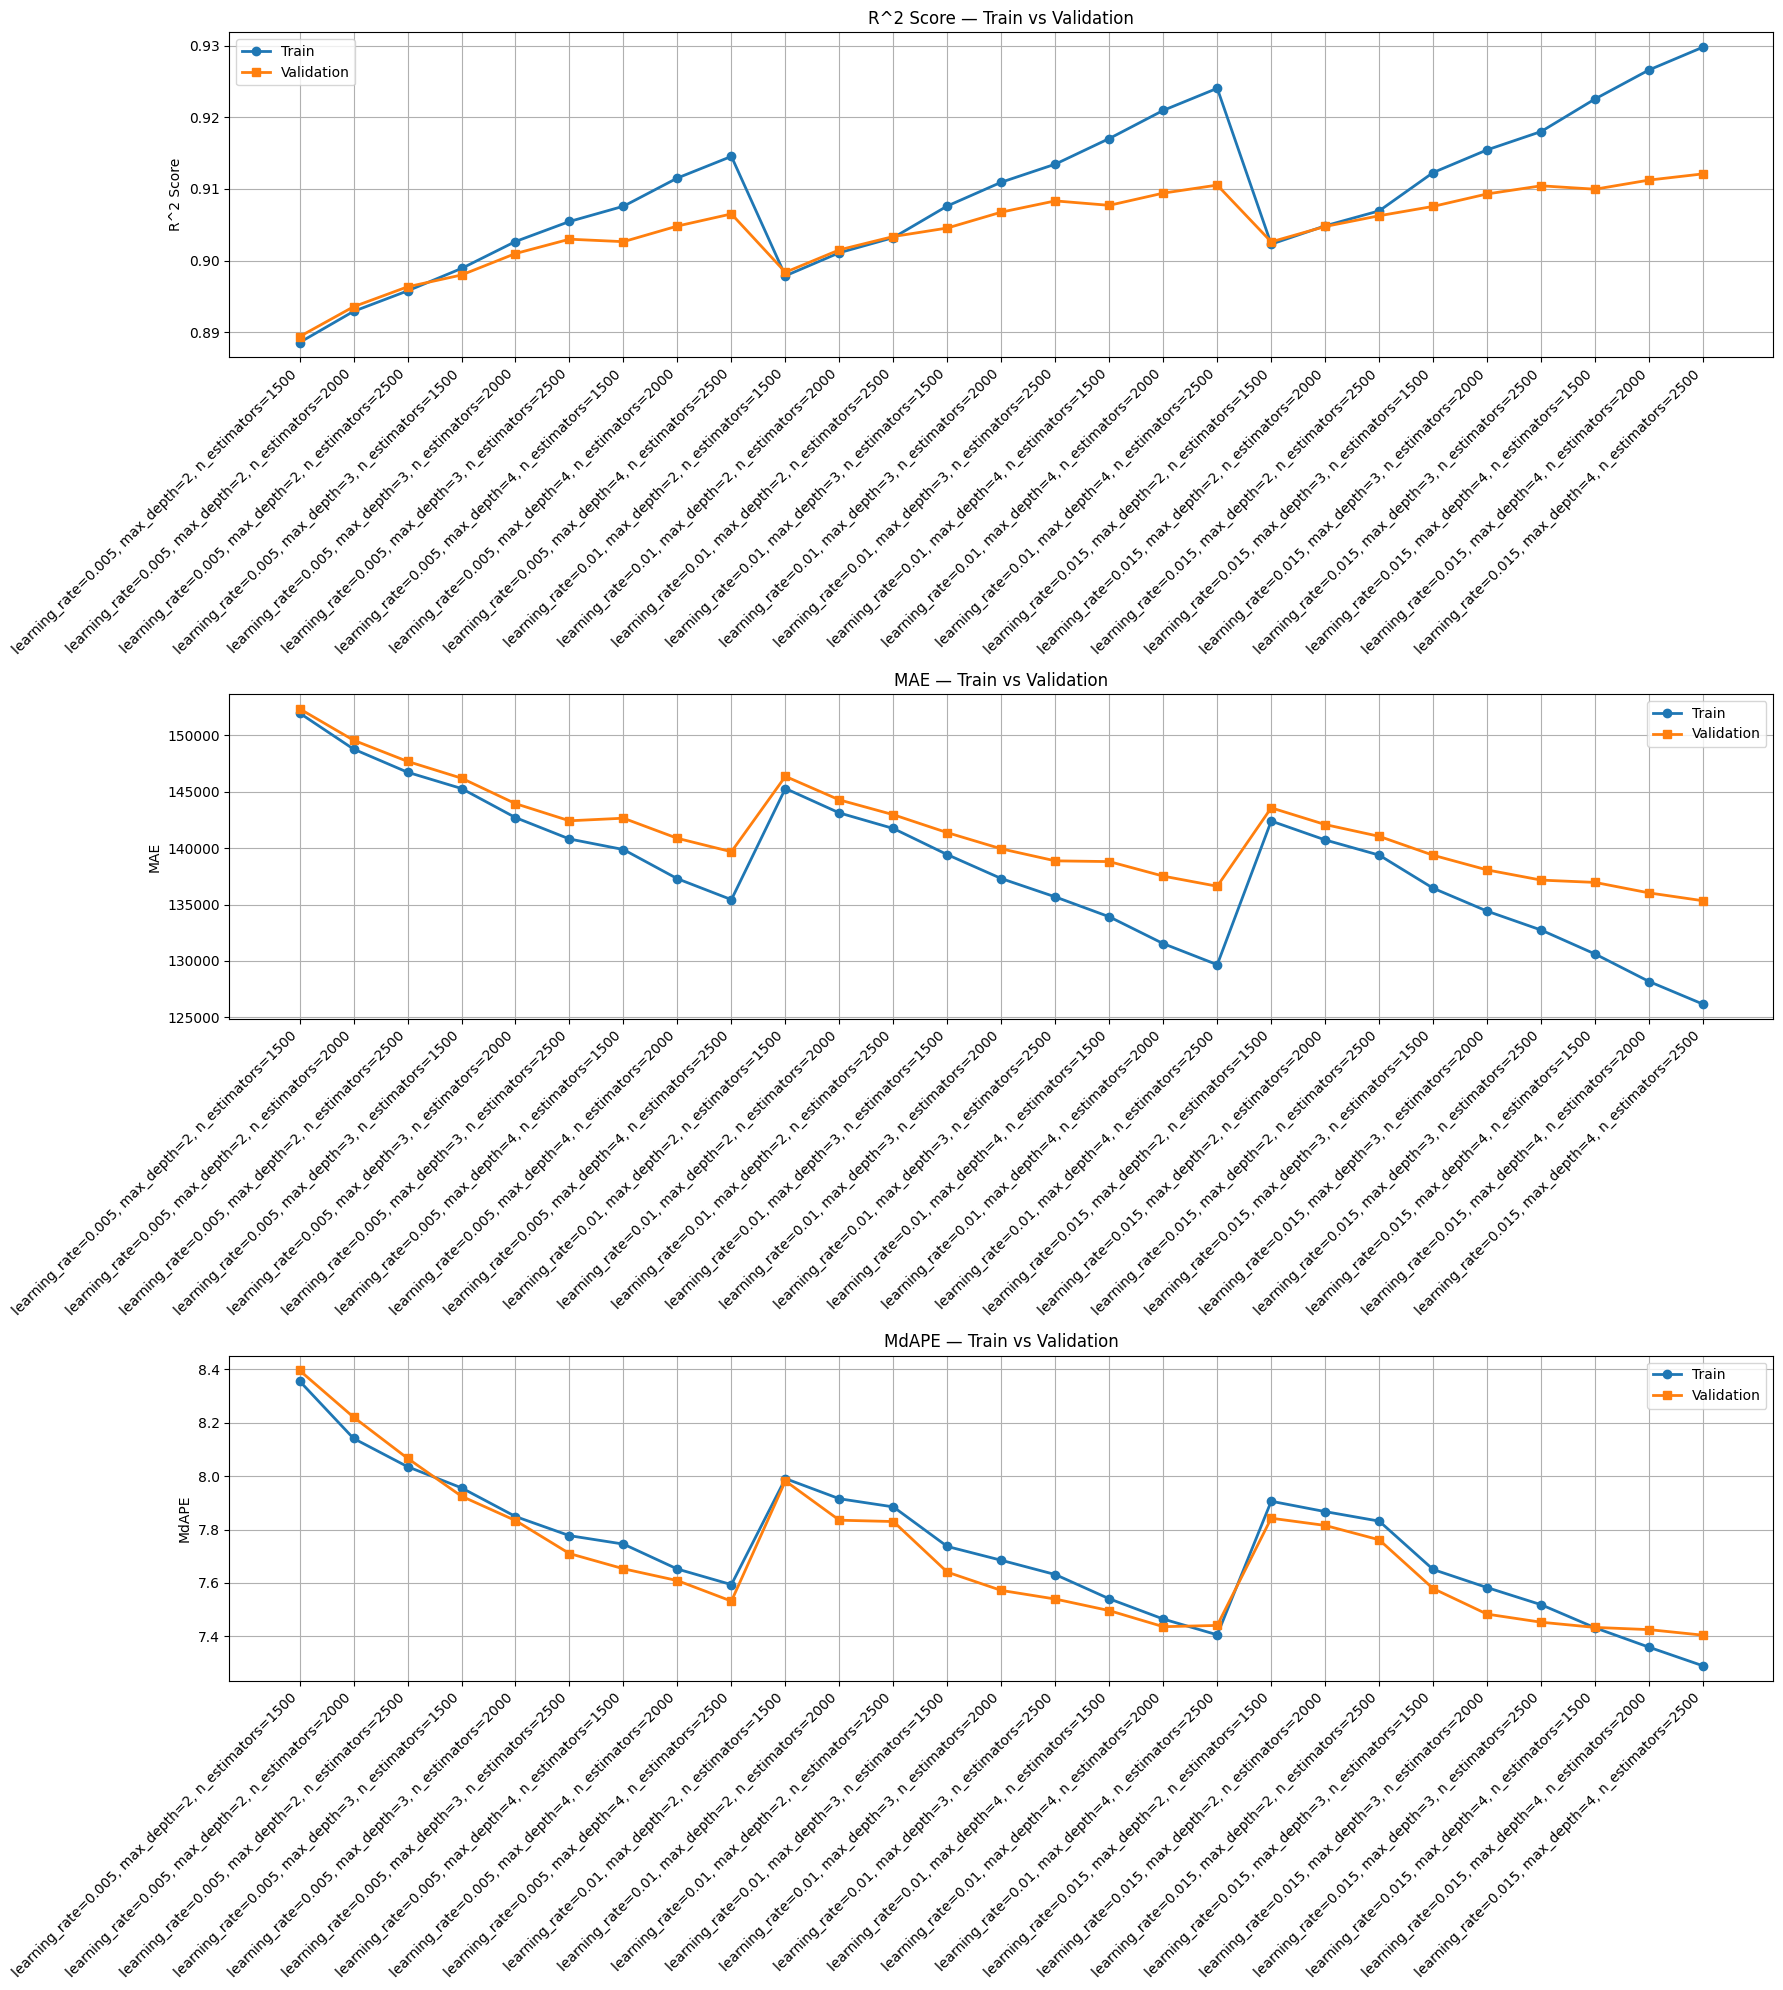

In [ ]:
xgb_params = {
    'max_depth': [2, 3, 4],
    'learning_rate': [0.005, 0.01, 0.015 ],
    'n_estimators': [1500, 2000, 2500]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.005, 'max_depth': 1, 'n_estimators': 2500}, 'Train R^2': 0.8750608263868134, 'Val R^2': 0.8756203242749298, 'Train RMSE': np.float64(306966.483697634), 'Val RMSE': np.float64(309958.3387410024), 'Train MAE': 159816.71154410002, 'Val MAE': 159296.85884409345, 'Train MdAPE': np.float64(8.856206678956324), 'Val MdAPE': np.float64(8.85215909090909)}
{'params': {'learning_rate': 0.005, 'max_depth': 1, 'n_estimators': 3000}, 'Train R^2': 0.877632404948172, 'Val R^2': 0.878087657727334, 'Train RMSE': np.float64(303790.96764815325), 'Val RMSE': np.float64(306868.6001062065), 'Train MAE': 157979.33860838157, 'Val MAE': 157590.10540939317, 'Train MdAPE': np.float64(8.705892844329638), 'Val MdAPE': np.float64(8.674021739130435)}
{'params': {'learning_rate': 0.005, 'max_depth': 1, 'n_estimators': 3500}, 'Train R^2': 0.8796854149627302, 'Val R^2': 0.8800230357450344, 'Train RMSE': np.float64(301231.77690478665), 'Val RMSE': np.float64(304423.0612853831), 'Train MAE': 

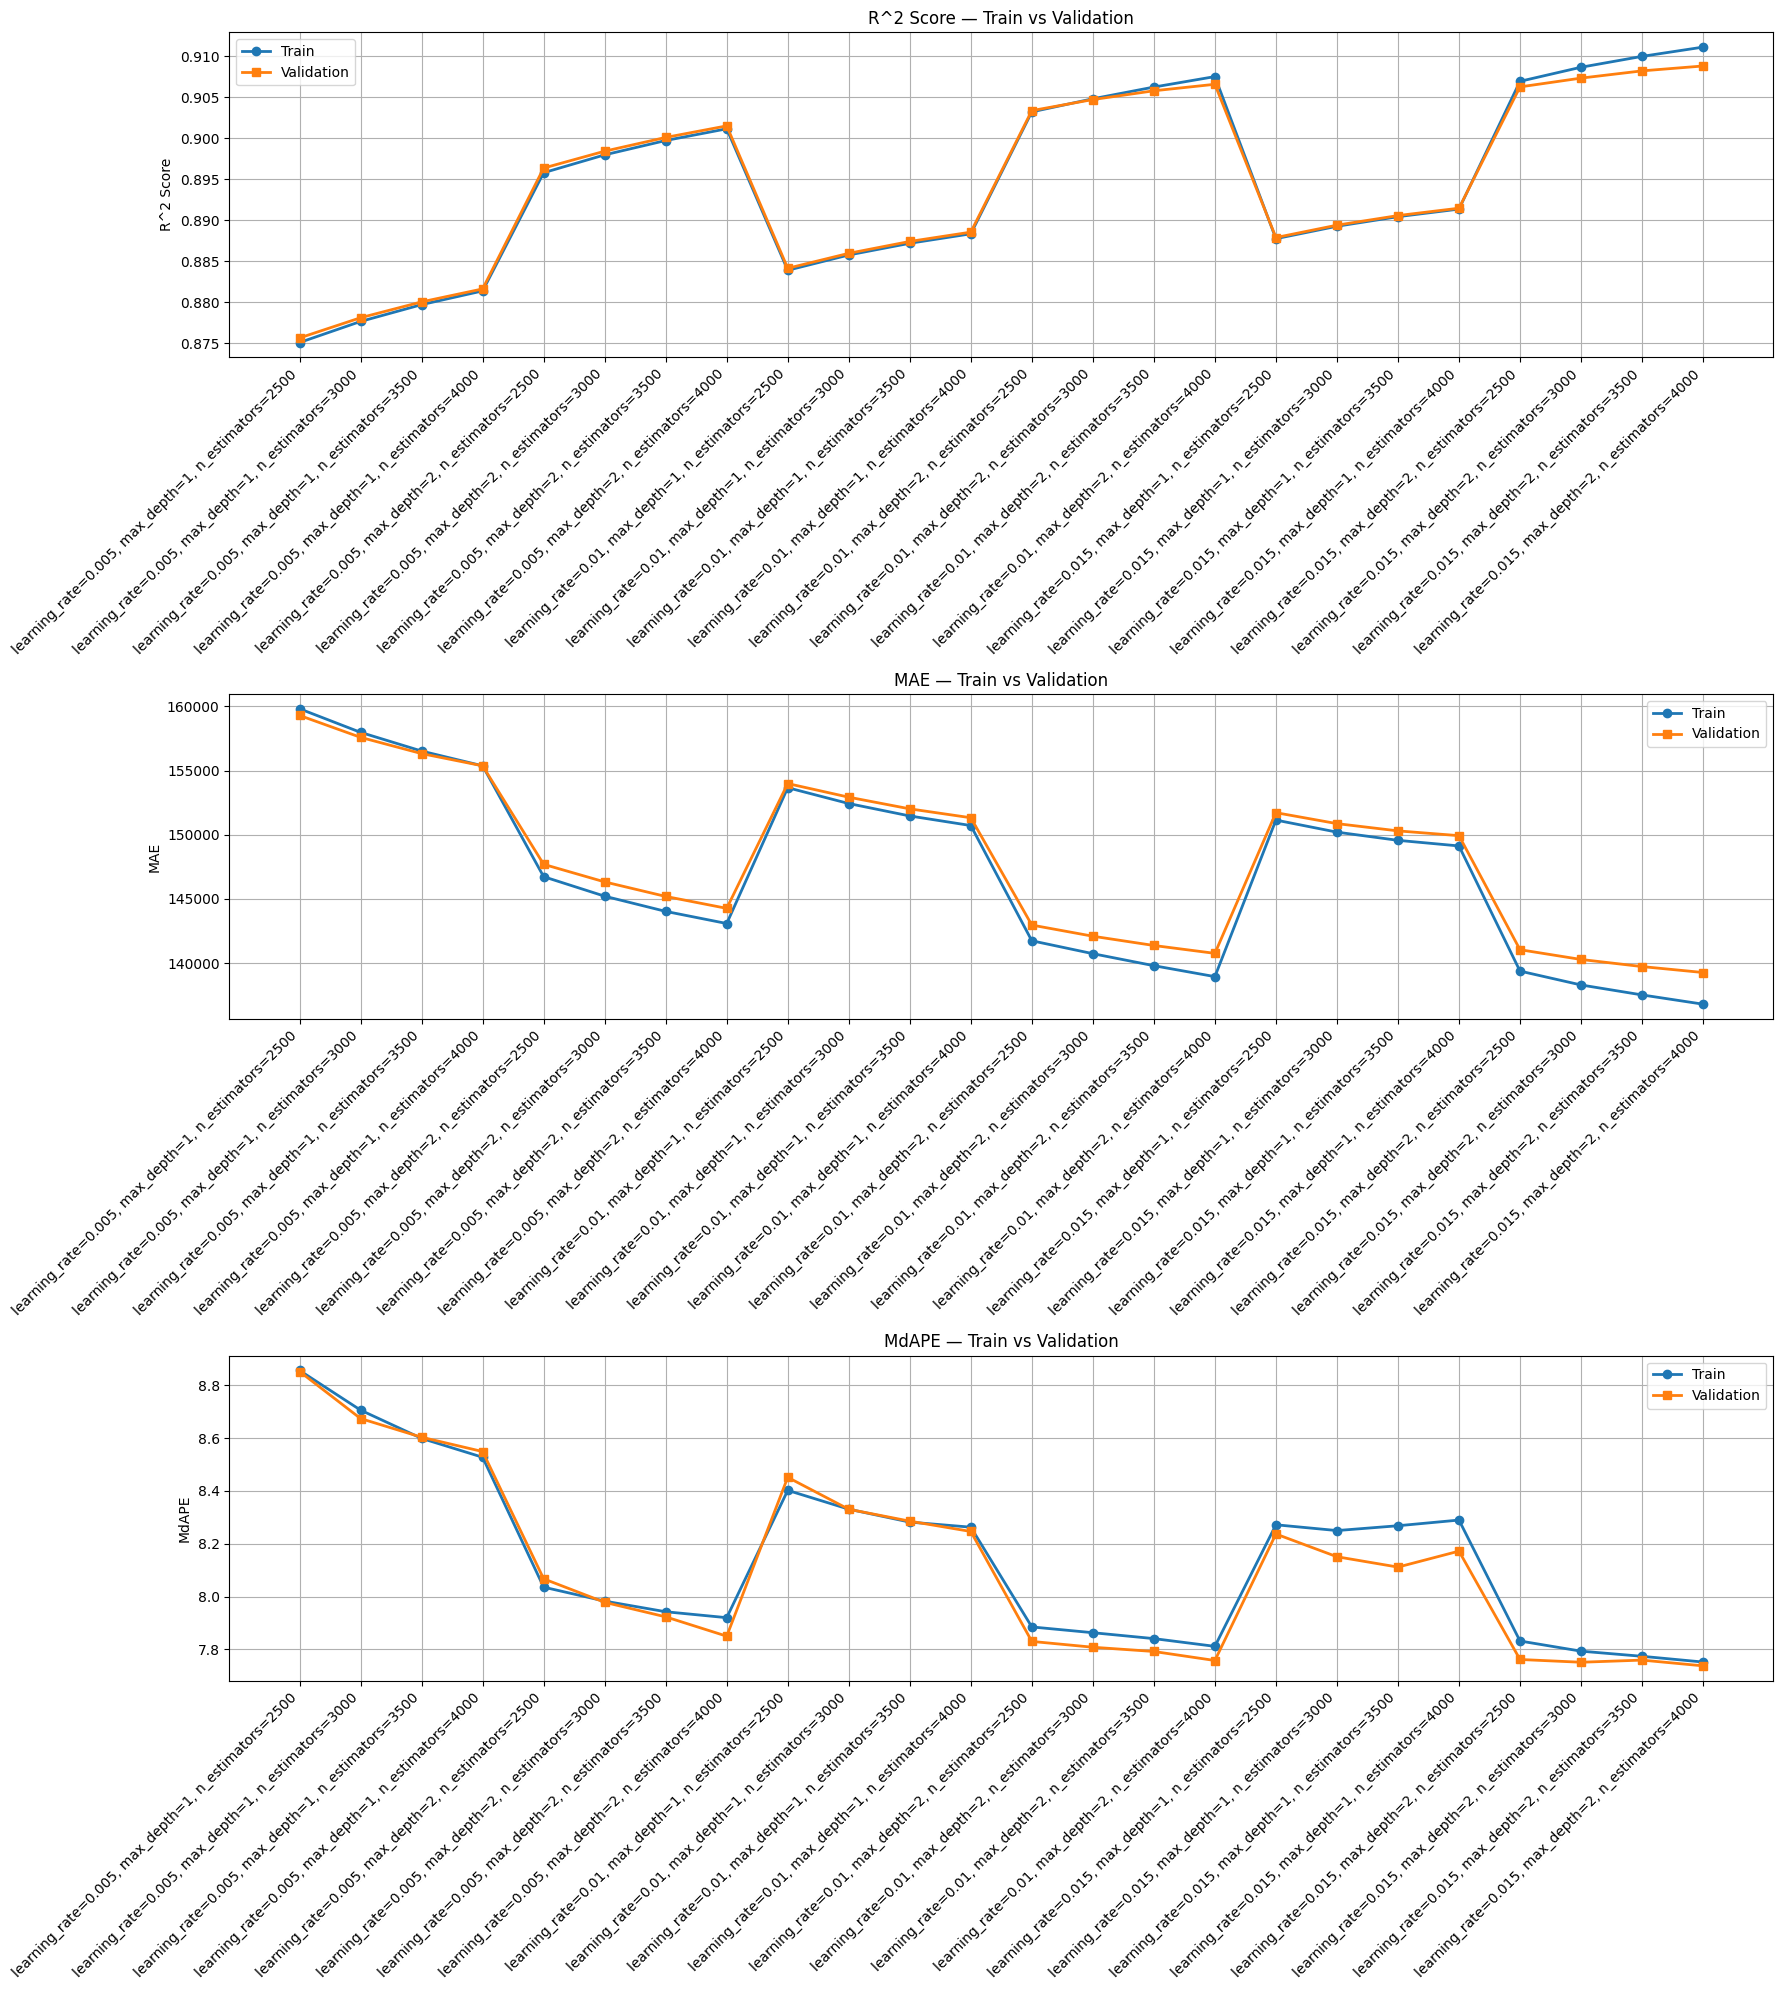

In [ ]:
xgb_params = {
    'max_depth': [1, 2],
    'learning_rate': [0.005, 0.01, 0.015 ],
    'n_estimators': [2500, 3000, 3500, 4000]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 3000}, 'Train R^2': 0.9048224173415607, 'Val R^2': 0.9047257346388845, 'Train RMSE': np.float64(267922.37231529655), 'Val RMSE': np.float64(271279.15176480945), 'Train MAE': 140739.23215341763, 'Val MAE': 142099.16202422185, 'Train MdAPE': np.float64(7.863187825390469), 'Val MdAPE': np.float64(7.808178718379858)}
{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 4000}, 'Train R^2': 0.9075312269662511, 'Val R^2': 0.9065910935186368, 'Train RMSE': np.float64(264082.238330704), 'Val RMSE': np.float64(268610.3597017199), 'Train MAE': 138951.24135775177, 'Val MAE': 140763.7578682345, 'Train MdAPE': np.float64(7.811523248792271), 'Val MdAPE': np.float64(7.757929292929293)}
{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 5000}, 'Train R^2': 0.9095577582578482, 'Val R^2': 0.9078936007099241, 'Train RMSE': np.float64(261172.41450489455), 'Val RMSE': np.float64(266731.0145441931), 'Train MAE': 

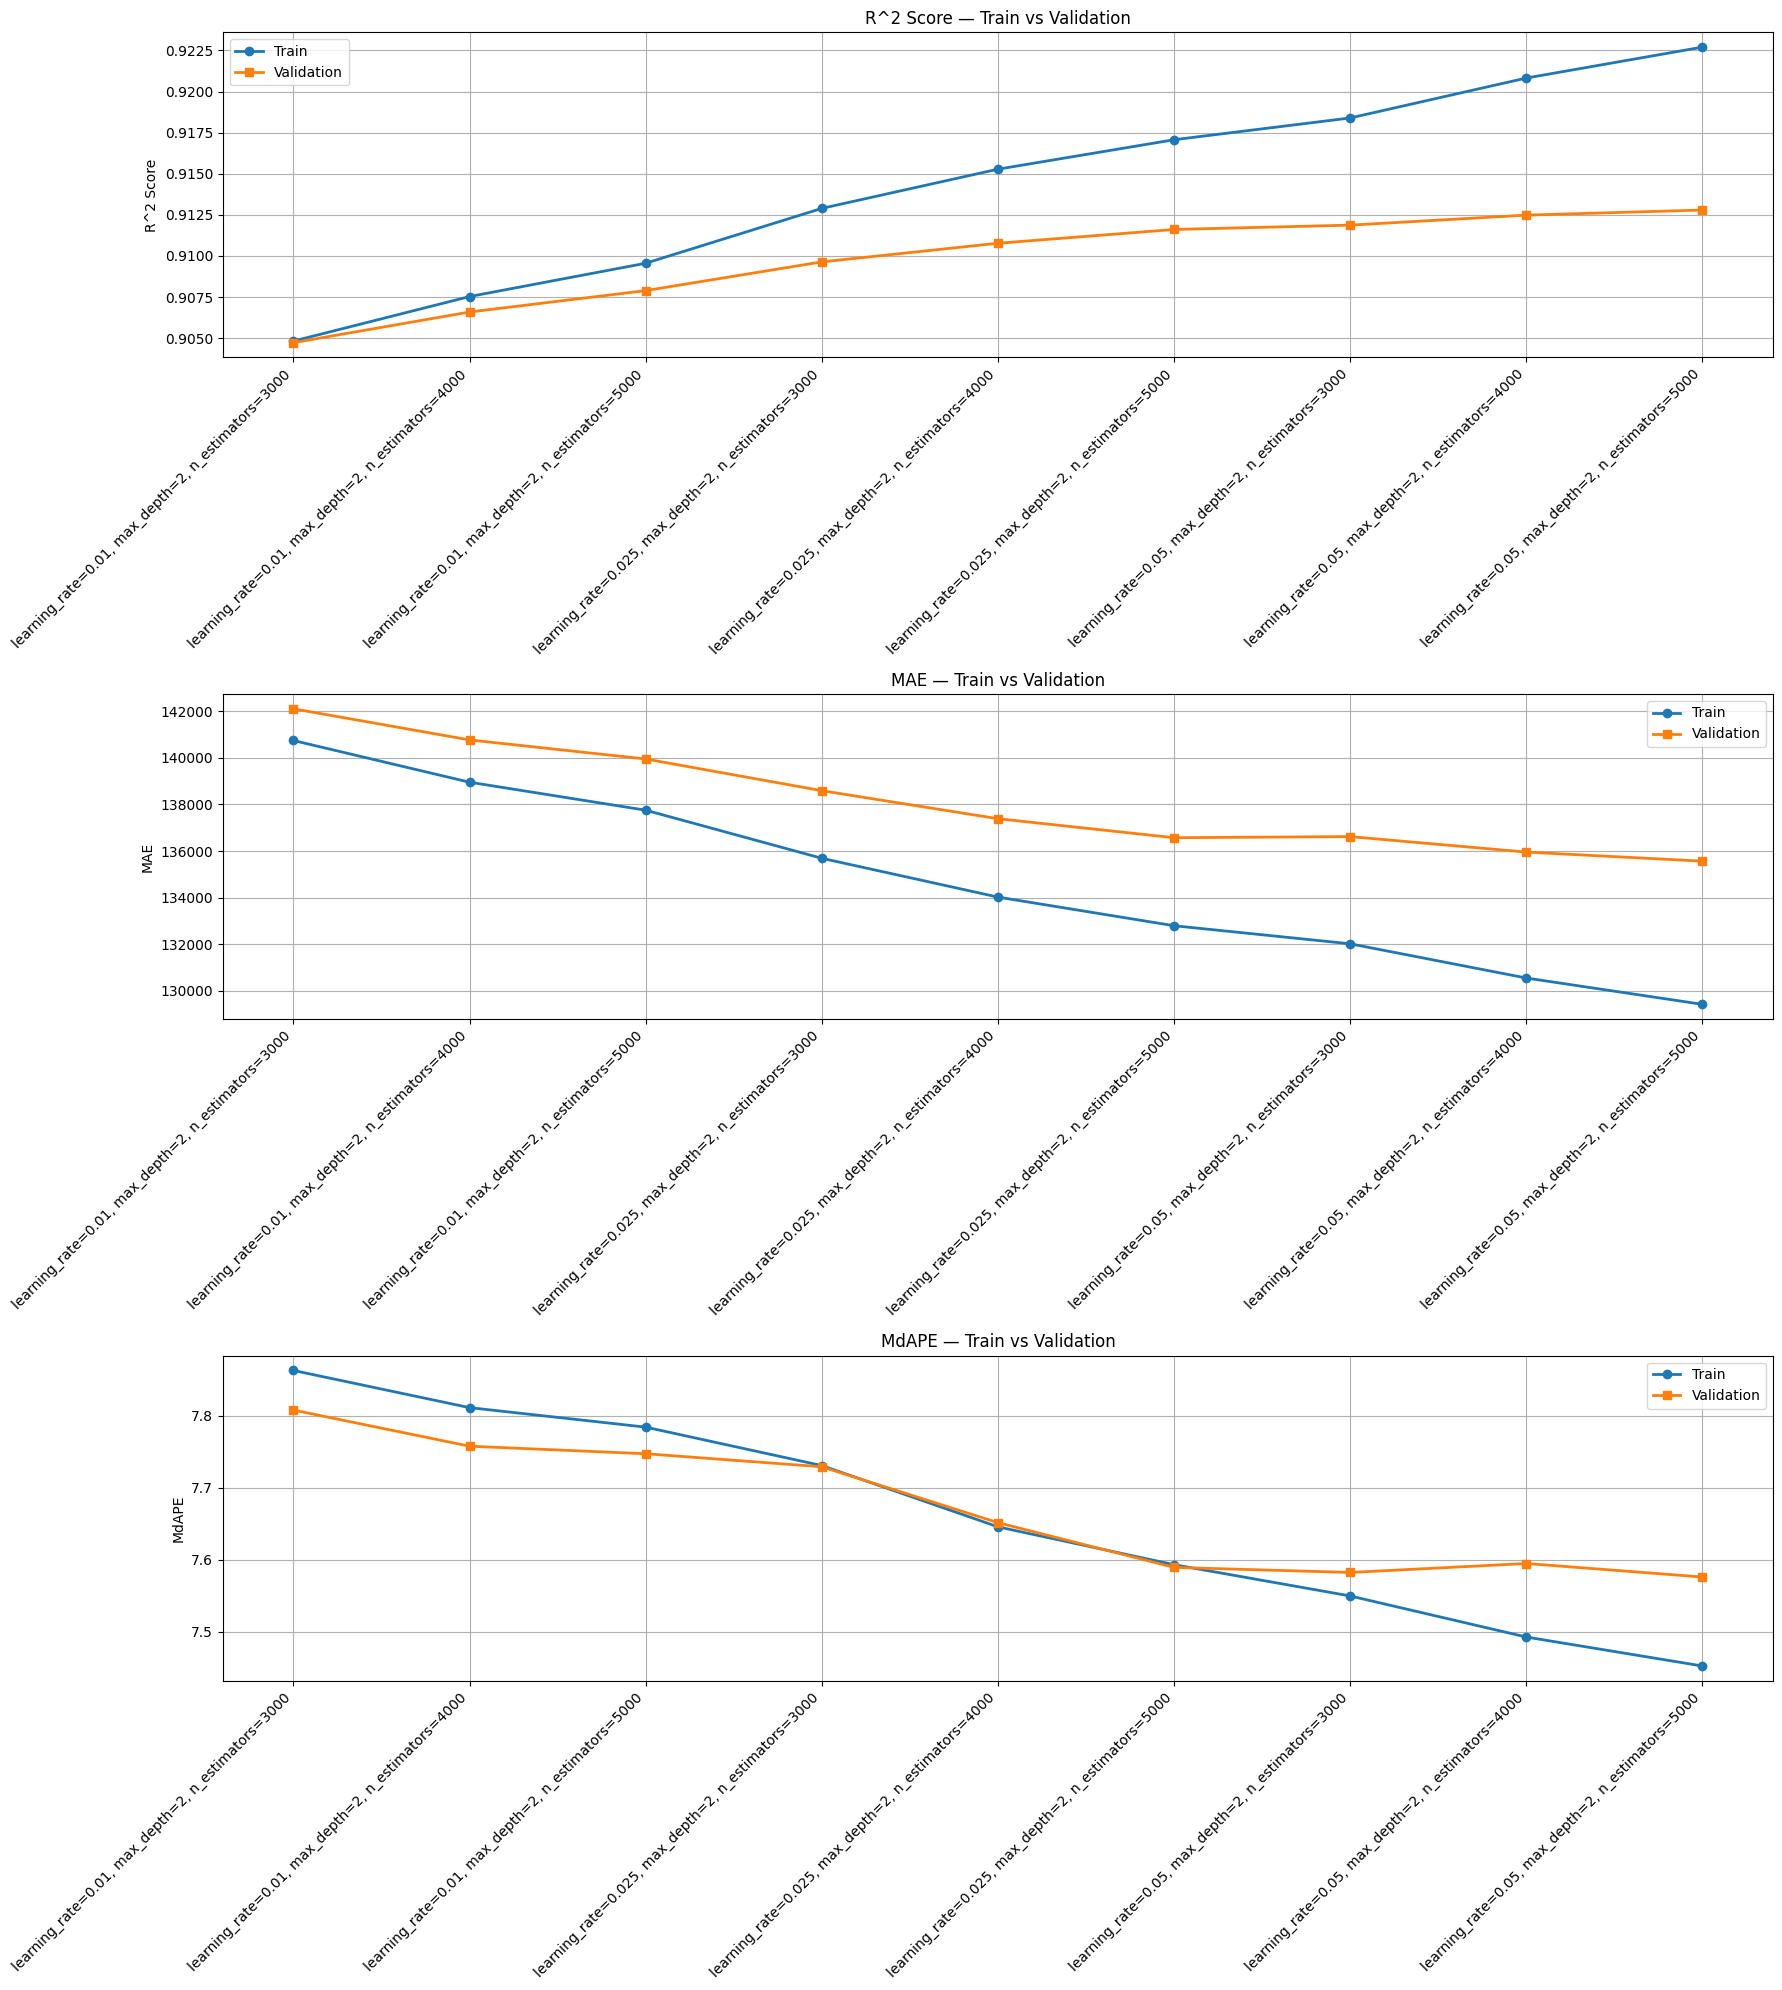

In [ ]:
xgb_params = {
    'max_depth': [2],
    'learning_rate': [0.01, 0.025, 0.05],
    'n_estimators': [3000, 4000, 5000]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 2000}, 'Train R^2': 0.8929411536577614, 'Val R^2': 0.8935858956797056, 'Train RMSE': np.float64(284153.44418156357), 'Val RMSE': np.float64(286700.34228890715), 'Train MAE': 148789.36343889876, 'Val MAE': 149574.29917267017, 'Train MdAPE': np.float64(8.14149325046779), 'Val MdAPE': np.float64(8.221185185185185)}
{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 3000}, 'Train R^2': 0.8979746017047349, 'Val R^2': 0.8984228041340749, 'Train RMSE': np.float64(277393.1895883866), 'Val RMSE': np.float64(280108.7814573986), 'Train MAE': 145216.002996082, 'Val MAE': 146329.1152603445, 'Train MdAPE': np.float64(7.982812184725585), 'Val MdAPE': np.float64(7.978208333333334)}
{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 4000}, 'Train R^2': 0.9011556514466801, 'Val R^2': 0.9015121758091226, 'Train RMSE': np.float64(273034.5249305274), 'Val RMSE': np.float64(275816.273173997), 'Train MAE': 1

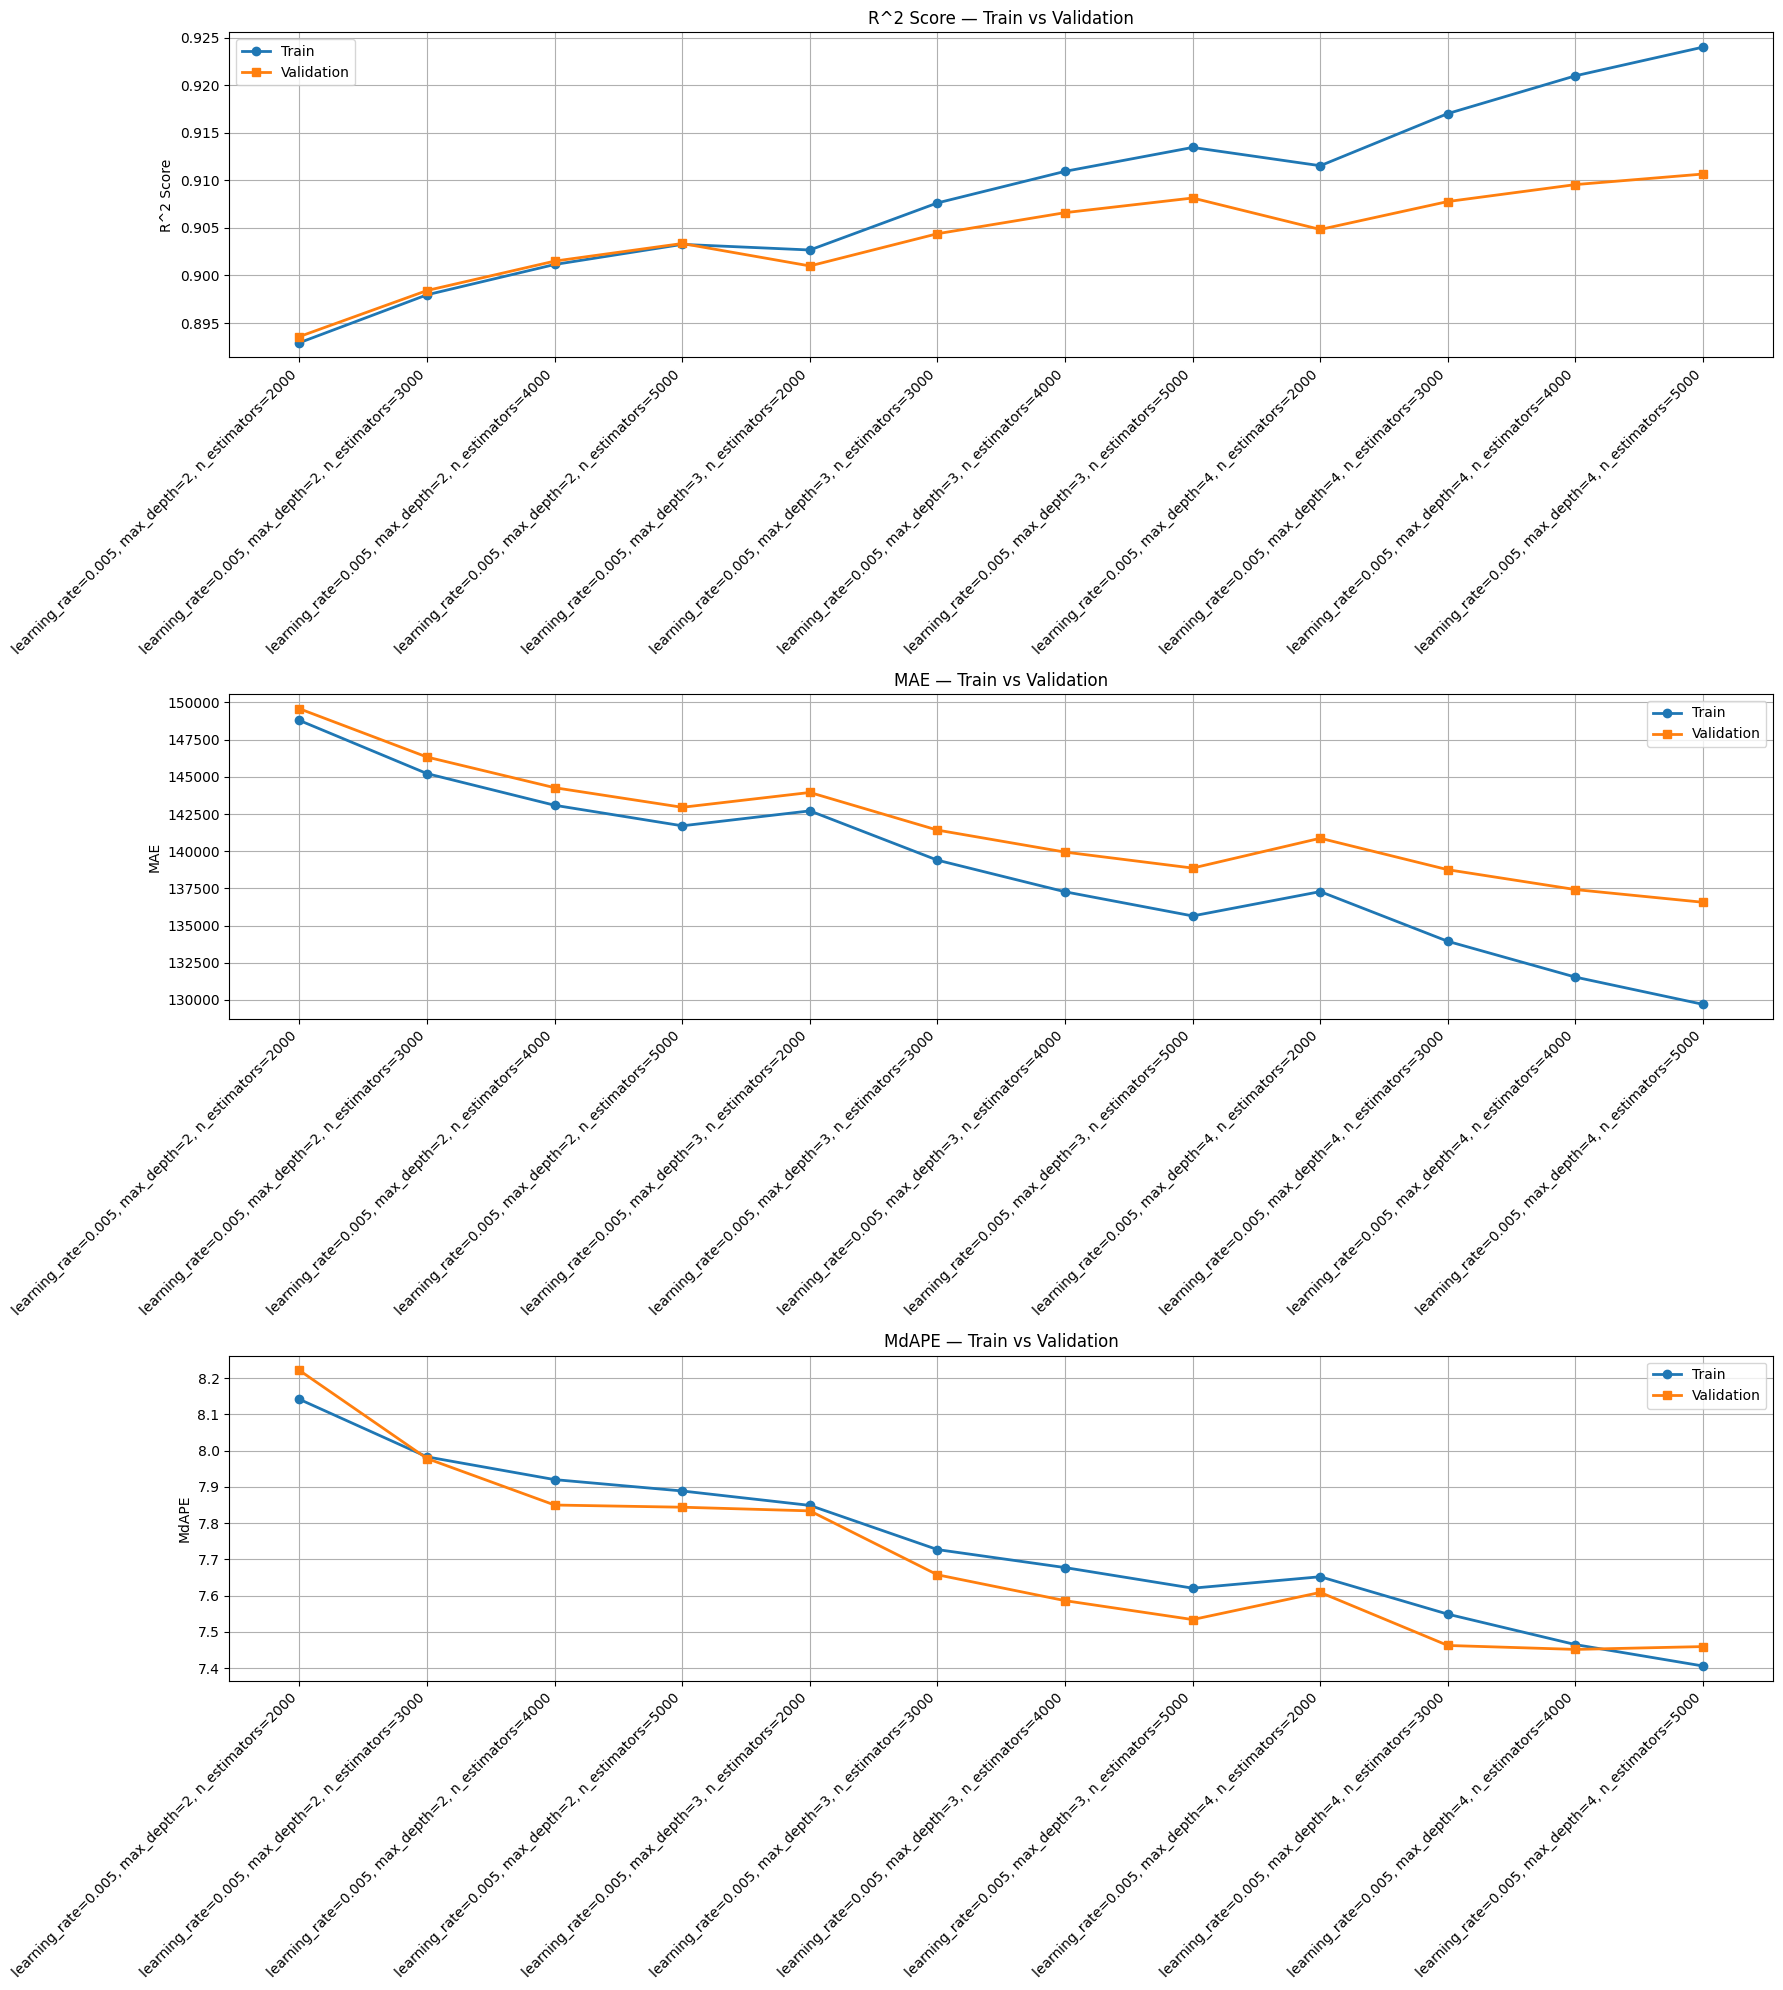

In [ ]:
xgb_params = {
    'max_depth': [2, 3, 4],
    'learning_rate': [0.005],
    'n_estimators': [2000, 3000, 4000, 5000]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 5000}, 'Train R^2': 0.9032689558369524, 'Val R^2': 0.903361382459411, 'Train RMSE': np.float64(270099.99910694), 'Val RMSE': np.float64(273214.64110906847), 'Train MAE': 141707.64973624874, 'Val MAE': 142952.5804515332, 'Train MdAPE': np.float64(7.888749775323534), 'Val MdAPE': np.float64(7.84396694214876)}
{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 6000}, 'Train R^2': 0.9048652308324623, 'Val R^2': 0.9047082575417157, 'Train RMSE': np.float64(267862.10611617), 'Val RMSE': np.float64(271304.03232761024), 'Train MAE': 140703.54931856837, 'Val MAE': 142084.80930359286, 'Train MdAPE': np.float64(7.8628681842055), 'Val MdAPE': np.float64(7.821039133738601)}
{'params': {'learning_rate': 0.005, 'max_depth': 2, 'n_estimators': 7000}, 'Train R^2': 0.9062700848862275, 'Val R^2': 0.9057514240495651, 'Train RMSE': np.float64(265876.9919834619), 'Val RMSE': np.float64(269814.9521132139), 'Train MAE': 13978

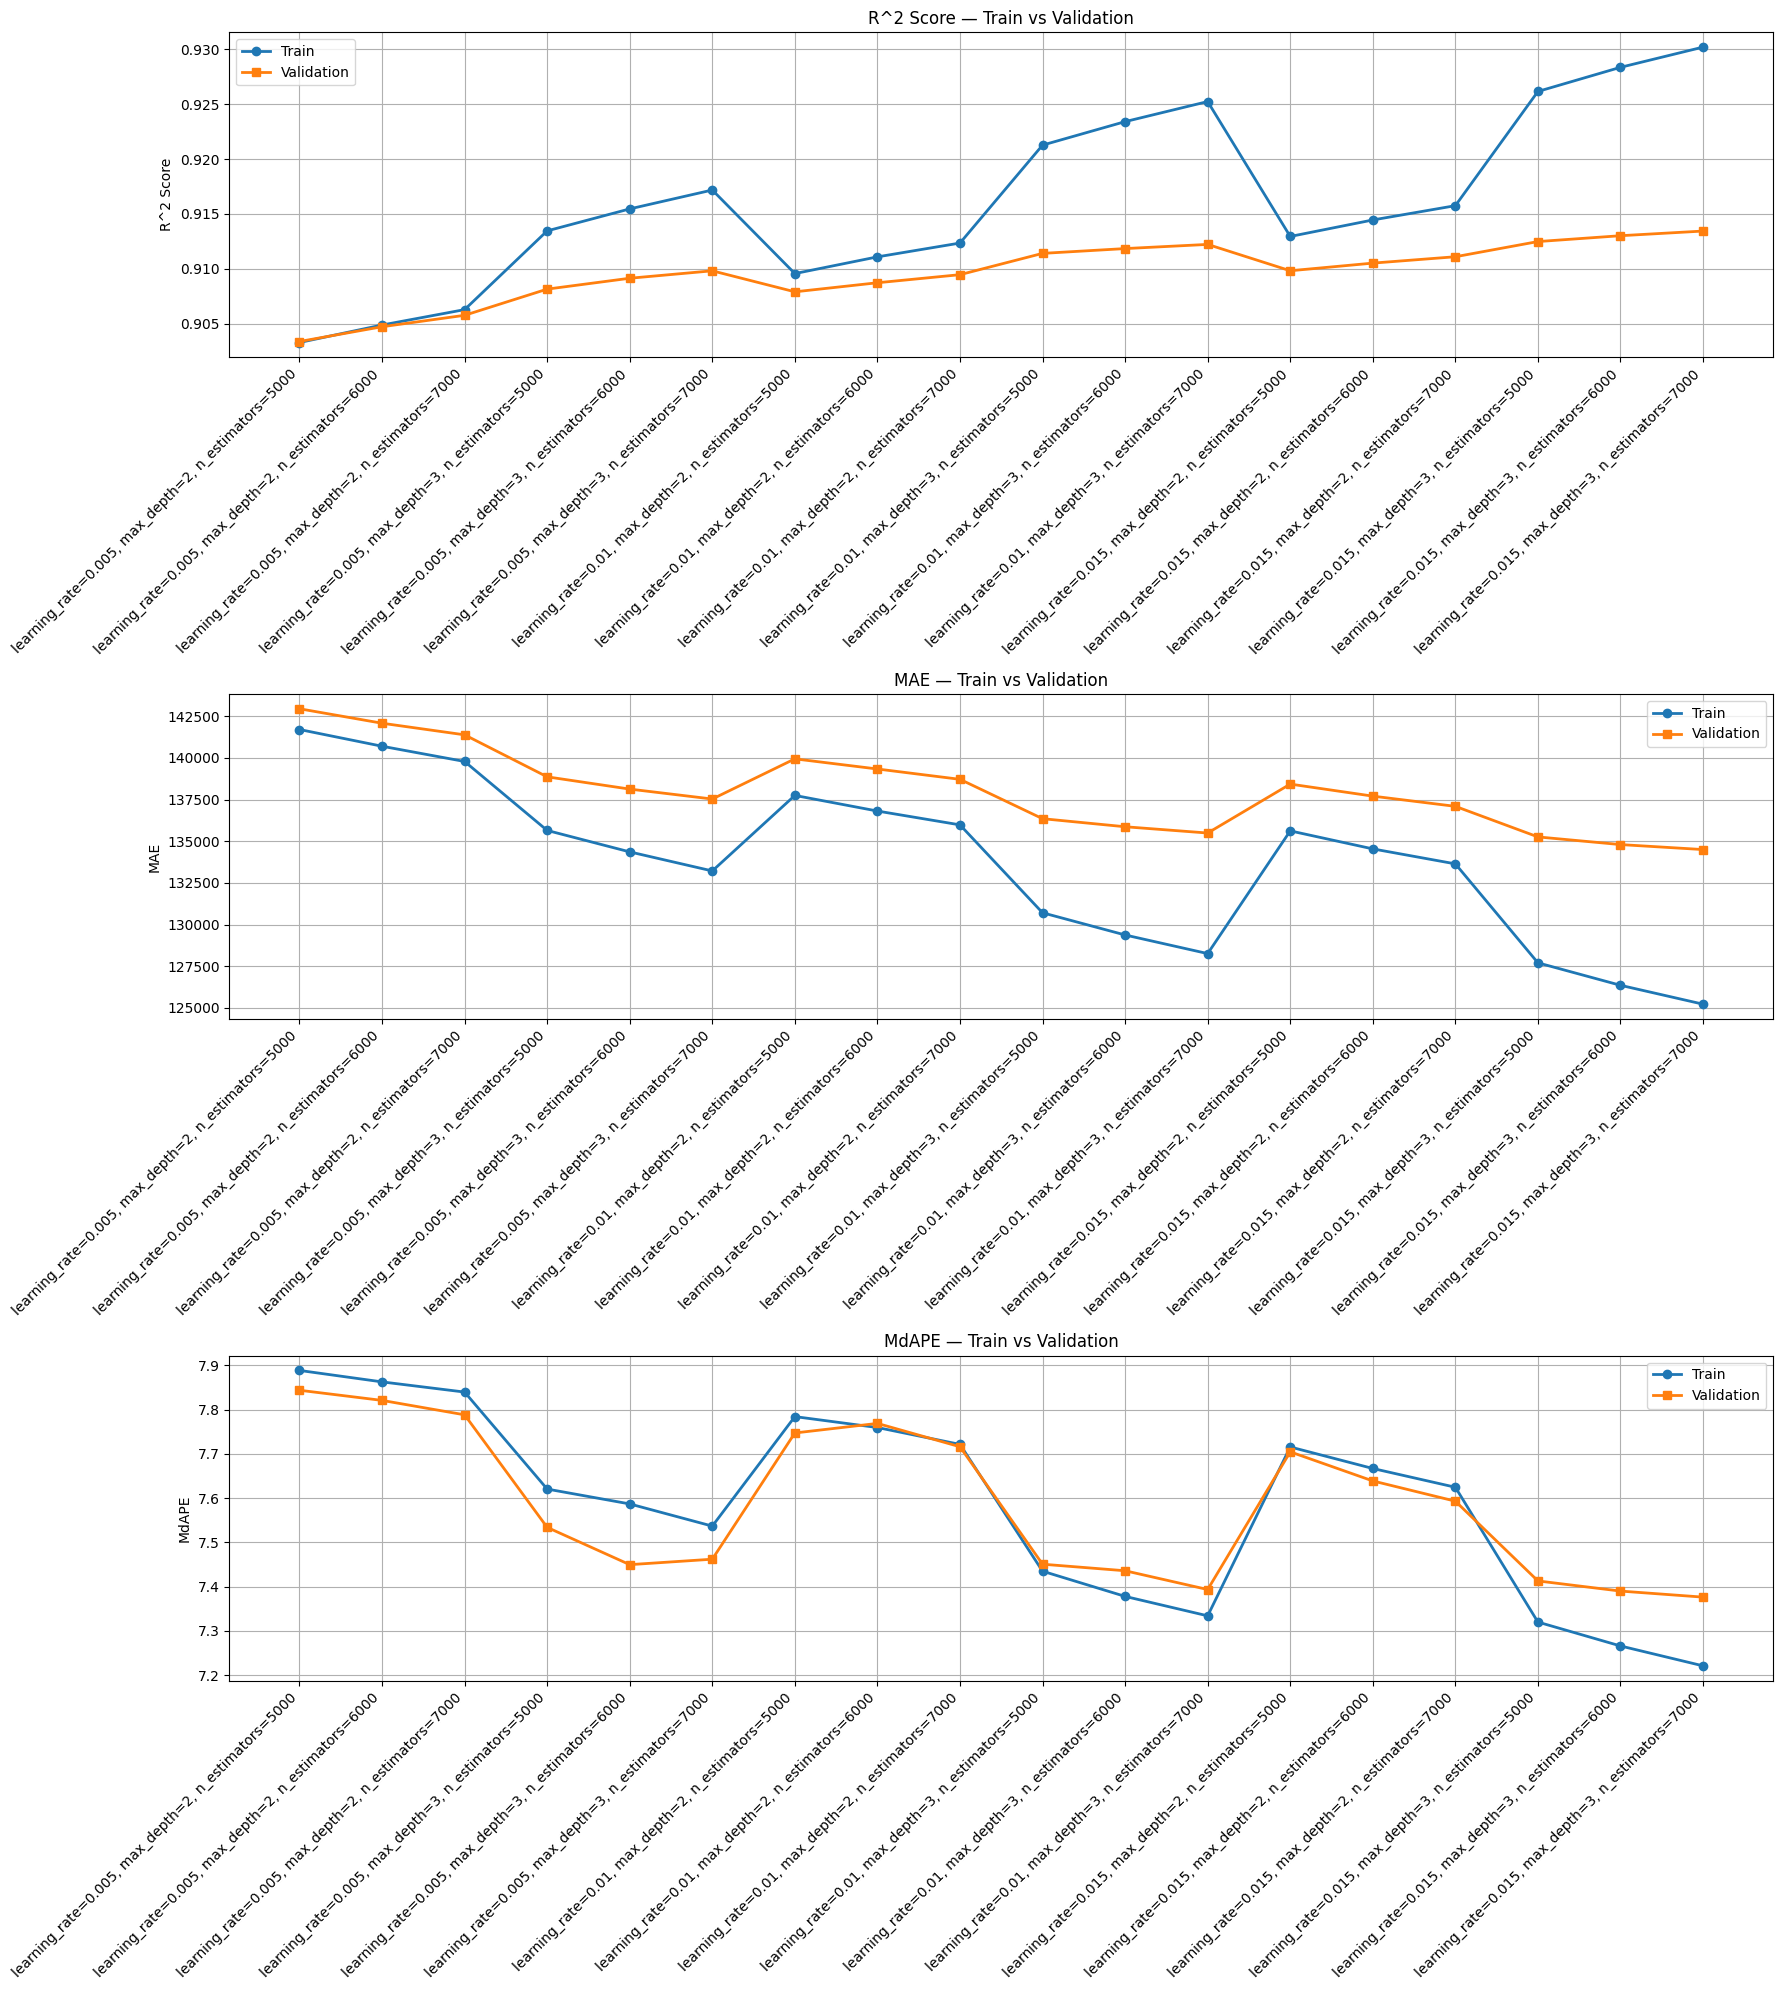

In [ ]:
xgb_params = {
    'max_depth': [2, 3],
    'learning_rate': [0.005, 0.01, 0.015],
    'n_estimators': [5000, 6000, 7000]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.015, 'max_depth': 4, 'n_estimators': 3000}, 'Train R^2': 0.9323591558480013, 'Val R^2': 0.9126990652152189, 'Train RMSE': np.float64(225863.55231631565), 'Val RMSE': np.float64(259679.73629811246), 'Train MAE': 124545.12329603989, 'Val MAE': 134872.65086000276, 'Train MdAPE': np.float64(7.222840508559919), 'Val MdAPE': np.float64(7.385339321357286)}
{'params': {'learning_rate': 0.015, 'max_depth': 4, 'n_estimators': 4000}, 'Train R^2': 0.9367364408799937, 'Val R^2': 0.9132378281855023, 'Train RMSE': np.float64(218433.10305566652), 'Val RMSE': np.float64(258877.2114092711), 'Train MAE': 121778.77000005264, 'Val MAE': 134327.15116595087, 'Train MdAPE': np.float64(7.135101705359858), 'Val MdAPE': np.float64(7.350381692112808)}
{'params': {'learning_rate': 0.015, 'max_depth': 4, 'n_estimators': 5000}, 'Train R^2': 0.9402839325916298, 'Val R^2': 0.913875732147457, 'Train RMSE': np.float64(212220.45662890535), 'Val RMSE': np.float64(257923.78058203717), 'Train 

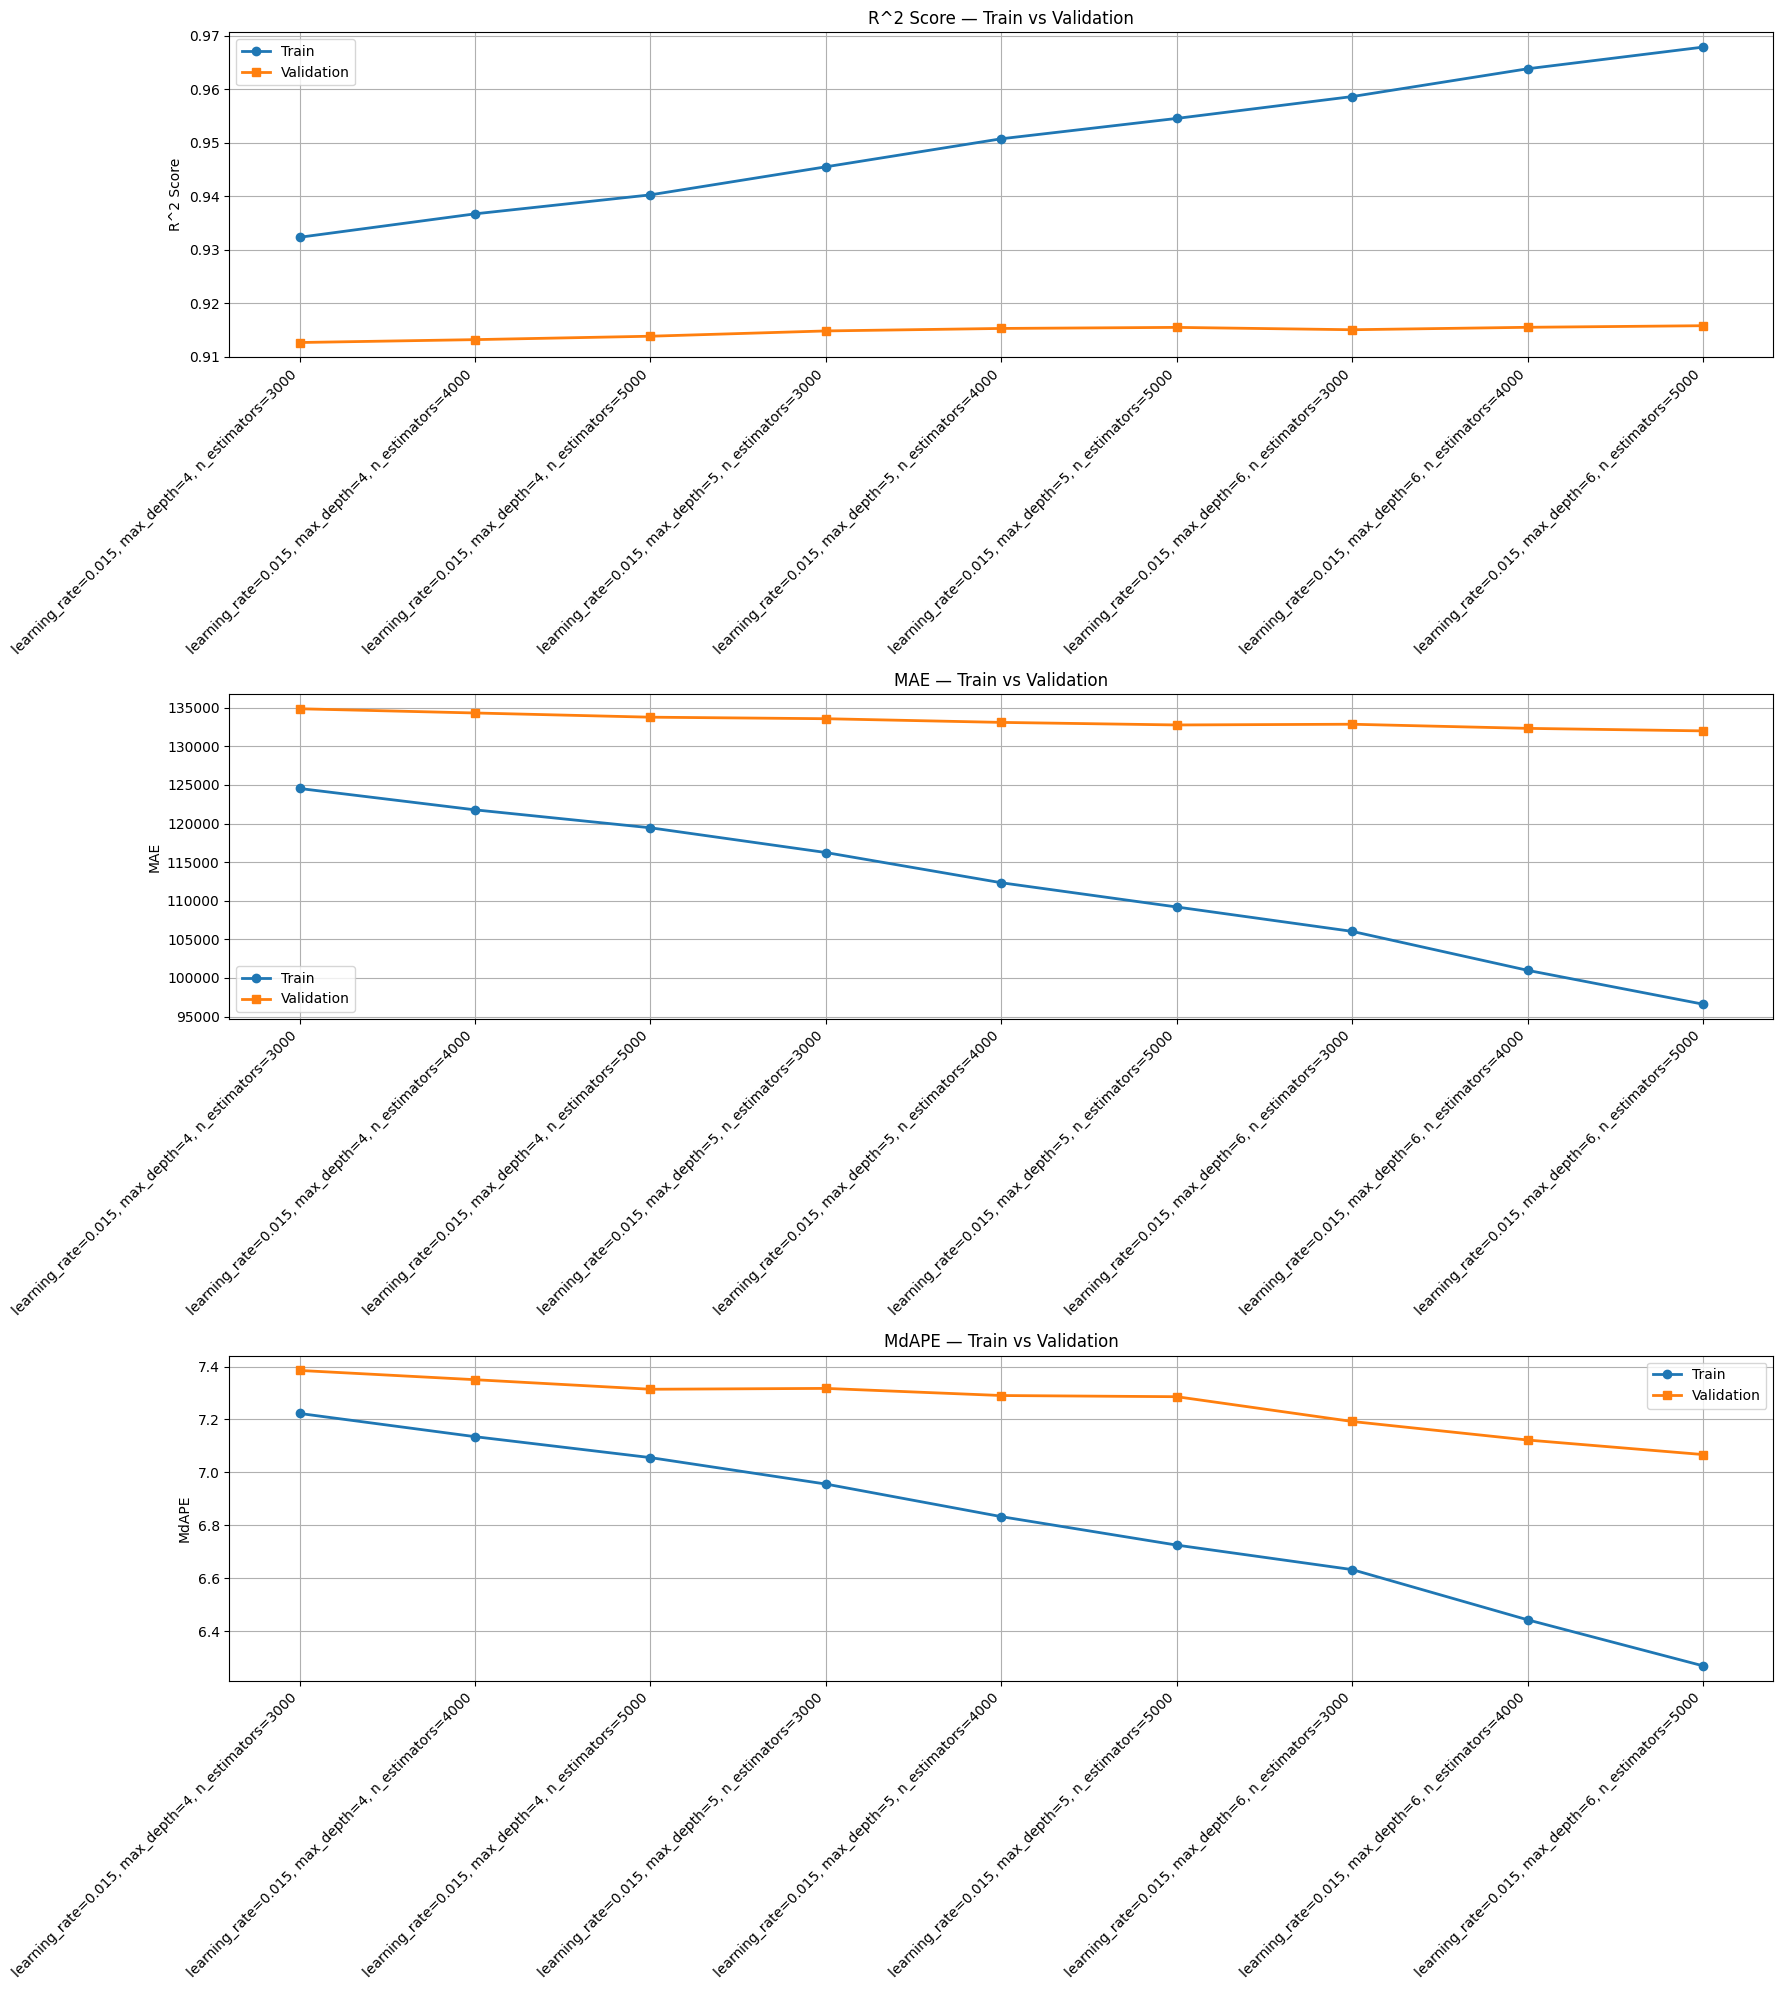

In [ ]:
xgb_params = {
    'max_depth': [4, 5, 6],
    'learning_rate': [0.015],
    'n_estimators': [3000, 4000, 5000]
}

xgb_results = train_xgboost_model(
    df_train,
    df_val,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

In [5]:
y_train = df_train["ClosePrice"].copy()
X_train = df_train.drop(columns=["ClosePrice"]).copy()

y_eval = df_val["ClosePrice"].copy()
X_eval = df_val.drop(columns=["ClosePrice"]).copy()

model = XGBRegressor(
    random_state=42,
    objective="reg:squarederror",
    learning_rate = 0.015,
    max_depth = 4,
    n_estimators = 3000

)

model.fit(X_train, y_train)

# Predictions
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_eval)

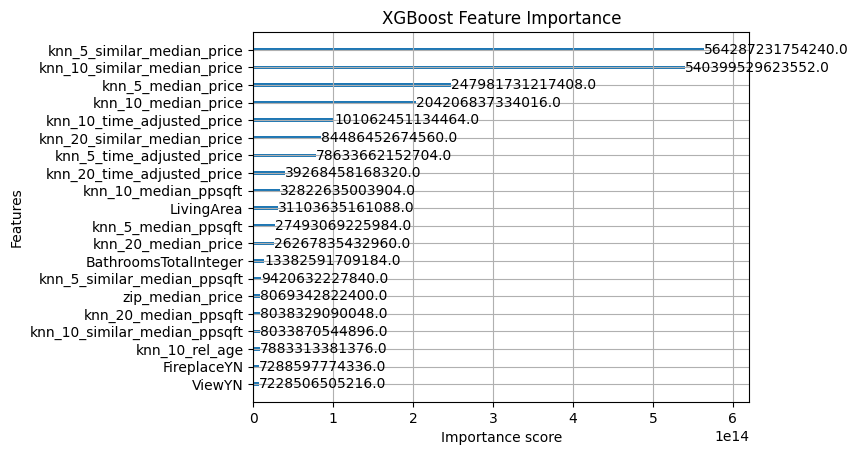

In [6]:
xgb.plot_importance(
    model,
    importance_type='gain',
    max_num_features=20
)

plt.title("XGBoost Feature Importance")
plt.show()

In [7]:
importance = model.get_booster().get_score(
    importance_type='gain'
)

importance_df = pd.DataFrame(
    importance.items(),
    columns=['Feature', 'Gain']
)

importance_df['Importance (%)'] = (
    importance_df['Gain'] /
    importance_df['Gain'].sum() * 100
)

importance_df = importance_df.sort_values(
    'Importance (%)',
    ascending=False
)

print(importance_df)

                         Feature          Gain  Importance (%)
54    knn_5_similar_median_price  5.642872e+14       25.853511
45   knn_10_similar_median_price  5.403995e+14       24.759067
50            knn_5_median_price  2.479817e+14       11.361587
41           knn_10_median_price  2.042068e+14        9.355987
49    knn_10_time_adjusted_price  1.010625e+14        4.630300
36   knn_20_similar_median_price  8.448645e+13        3.870850
58     knn_5_time_adjusted_price  7.863366e+13        3.602698
40    knn_20_time_adjusted_price  3.926846e+13        1.799133
43          knn_10_median_ppsqft  3.282264e+13        1.503809
2                     LivingArea  3.110364e+13        1.425051
52           knn_5_median_ppsqft  2.749307e+13        1.259629
32           knn_20_median_price  2.626784e+13        1.203493
1          BathroomsTotalInteger  1.338259e+13        0.613140
56   knn_5_similar_median_ppsqft  9.420632e+12        0.431618
28              zip_median_price  8.069343e+12        0

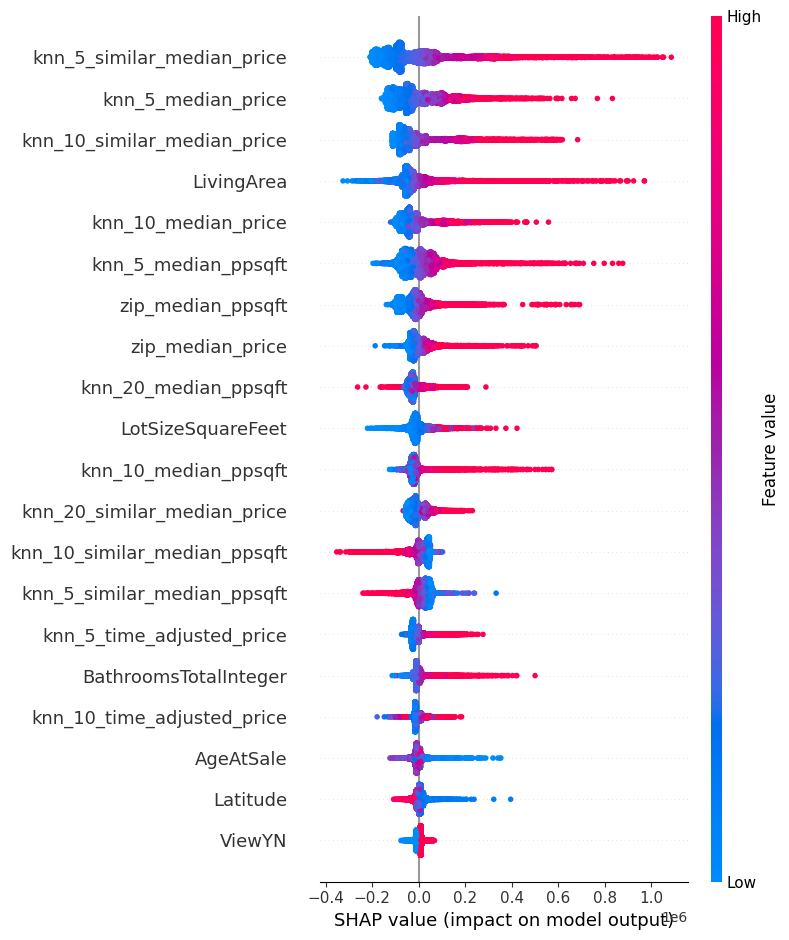

In [8]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_eval)

shap.summary_plot(shap_values, X_eval)

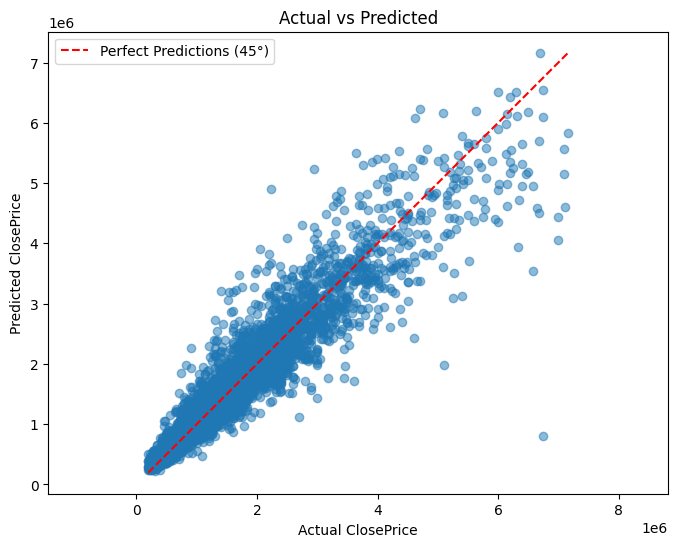

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(y_eval, y_pred_val, alpha=0.5)

# Add 45-degree reference line
min_val = min(y_eval.min(), y_pred_val.min())
max_val = max(y_eval.max(), y_pred_val.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    label='Perfect Predictions (45°)'
)

plt.xlabel('Actual ClosePrice')
plt.ylabel('Predicted ClosePrice')
plt.title('Actual vs Predicted')

plt.legend()
plt.axis('equal')
plt.show()

## Summary of XGBoost for this Data Set

Several different learning rates, max depths and number of trees showed similar results. Some key results are given in the table below for comparison.

| Learning Rate | Max Depth | Number of Trees | R-Squared | MAE | MdAPE |
|----------|----------|----------|----------|----------|----------|
| 0.015 | 4 | 3000 |0.9126 | \$134,501 | 7.38% |
| 0.2 | 3 | 500 | 0.9105 | \$136,873 | 7.57% |
| 0.005 | 2 | 4000 | 0.9015 | \$144,268 | 7.85% |
| 0.005 | 3 | 7000 | 0.9098 | \$137,535 | 7.46% |



## Model Comparison for this Data Set

| Model | Model Details | R-Squared | MAE | MdAPE |
|----------|----------|----------|----------|----------|
| Linear Regression |  | 0.8917 | \$156,731 | 9.82% |
| Decision Tree |  | 0.8034 | \$206,744 | 11.46% |
| Random Forest | Max Depth: 10, Num Trees: 15 (Min 2 samples/leaf) | 0.8833 | \$154,875 | 8.18% |
| XGBoost | Max Depth: 4, Num Trees: 3000, Learning Rate: 0.015 | 0.9126 | \$134,501 | 7.38% |

## Best Performing Model Overall
| Model | Data | Features | R-Squared | MAE | MdAPE | NOTE |
|---|---|---|---|---|---|---|
| Linear Regression | 24 mo using 15mo subset | Original Full | 0.8883 | \$162,018 | 10.85% |
| Linear Regression | 24 mo using 6mo subset | knn 5 mdn price | 0.8438 | \$156,963 | 6.45% | Best MdAPE achieved with just one feature
| Decision Tree | 28 mo/15mo | Original Full | 0.8370 | \$183,151 | 9.80% |
| Random Forest | 24 mo using 6mo subset | Original Full | 0.9032 | \$135,377 | 6.77% | Max Depth: 10, Number of Trees: 15 (no min samples/leaf)
| XGBoost | 18 mo / 6 mo (hybrid) | Original + New | 0.9126 | \$134,501 | 7.38% | Only 1 data set considered for XGBoost |



# Part 2

In [10]:
app_features = [
    "ClosePrice", # target
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "bed_bath_ratio",
    "LivingArea",
    "LotSizeSquareFeet",
    "FireplaceYN",
    "knn_5_similar_median_price",
    "knn_10_similar_median_price",
    "knn_20_similar_median_price",
    "knn_5_median_price",
    "knn_10_median_price",
    "knn_20_median_price",
    "knn_5_time_adjusted_price",
    "knn_10_time_adjusted_price",
    "knn_20_time_adjusted_price",
    "knn_5_similar_median_ppsqft",
    "knn_10_similar_median_ppsqft",
    "knn_20_similar_median_ppsqft",
    "knn_5_median_ppsqft",
    "knn_10_median_ppsqft",
    "knn_20_median_ppsqft",
    "zip_median_price",
    "zip_median_ppsqft"
]

In [11]:
# Data sets for just the subset of features
df_train_app = df_train[app_features].copy()
df_val_app = df_val[app_features].copy()

{'params': {'learning_rate': 0.001, 'max_depth': 2, 'n_estimators': 100}, 'Train R^2': 0.132825585857268, 'Val R^2': 0.1296769966575534, 'Train RMSE': np.float64(808713.834667971), 'Val RMSE': np.float64(819915.026358582), 'Train MAE': 549923.1395899398, 'Val MAE': 559248.3623298235, 'Train MdAPE': np.float64(43.38335393258427), 'Val MdAPE': np.float64(43.50812903225806)}
{'params': {'learning_rate': 0.001, 'max_depth': 2, 'n_estimators': 500}, 'Train R^2': 0.4810539644544677, 'Val R^2': 0.4737872020363225, 'Train RMSE': np.float64(625608.6489100686), 'Val RMSE': np.float64(637542.7591215591), 'Train MAE': 404151.55071432743, 'Val MAE': 412352.09570471966, 'Train MdAPE': np.float64(29.46357965225564), 'Val MdAPE': np.float64(30.054243243243246)}
{'params': {'learning_rate': 0.001, 'max_depth': 2, 'n_estimators': 1000}, 'Train R^2': 0.6880796287211414, 'Val R^2': 0.6809633301103808, 'Train RMSE': np.float64(485024.3188331673), 'Val RMSE': np.float64(496419.5953269032), 'Train MAE': 2942

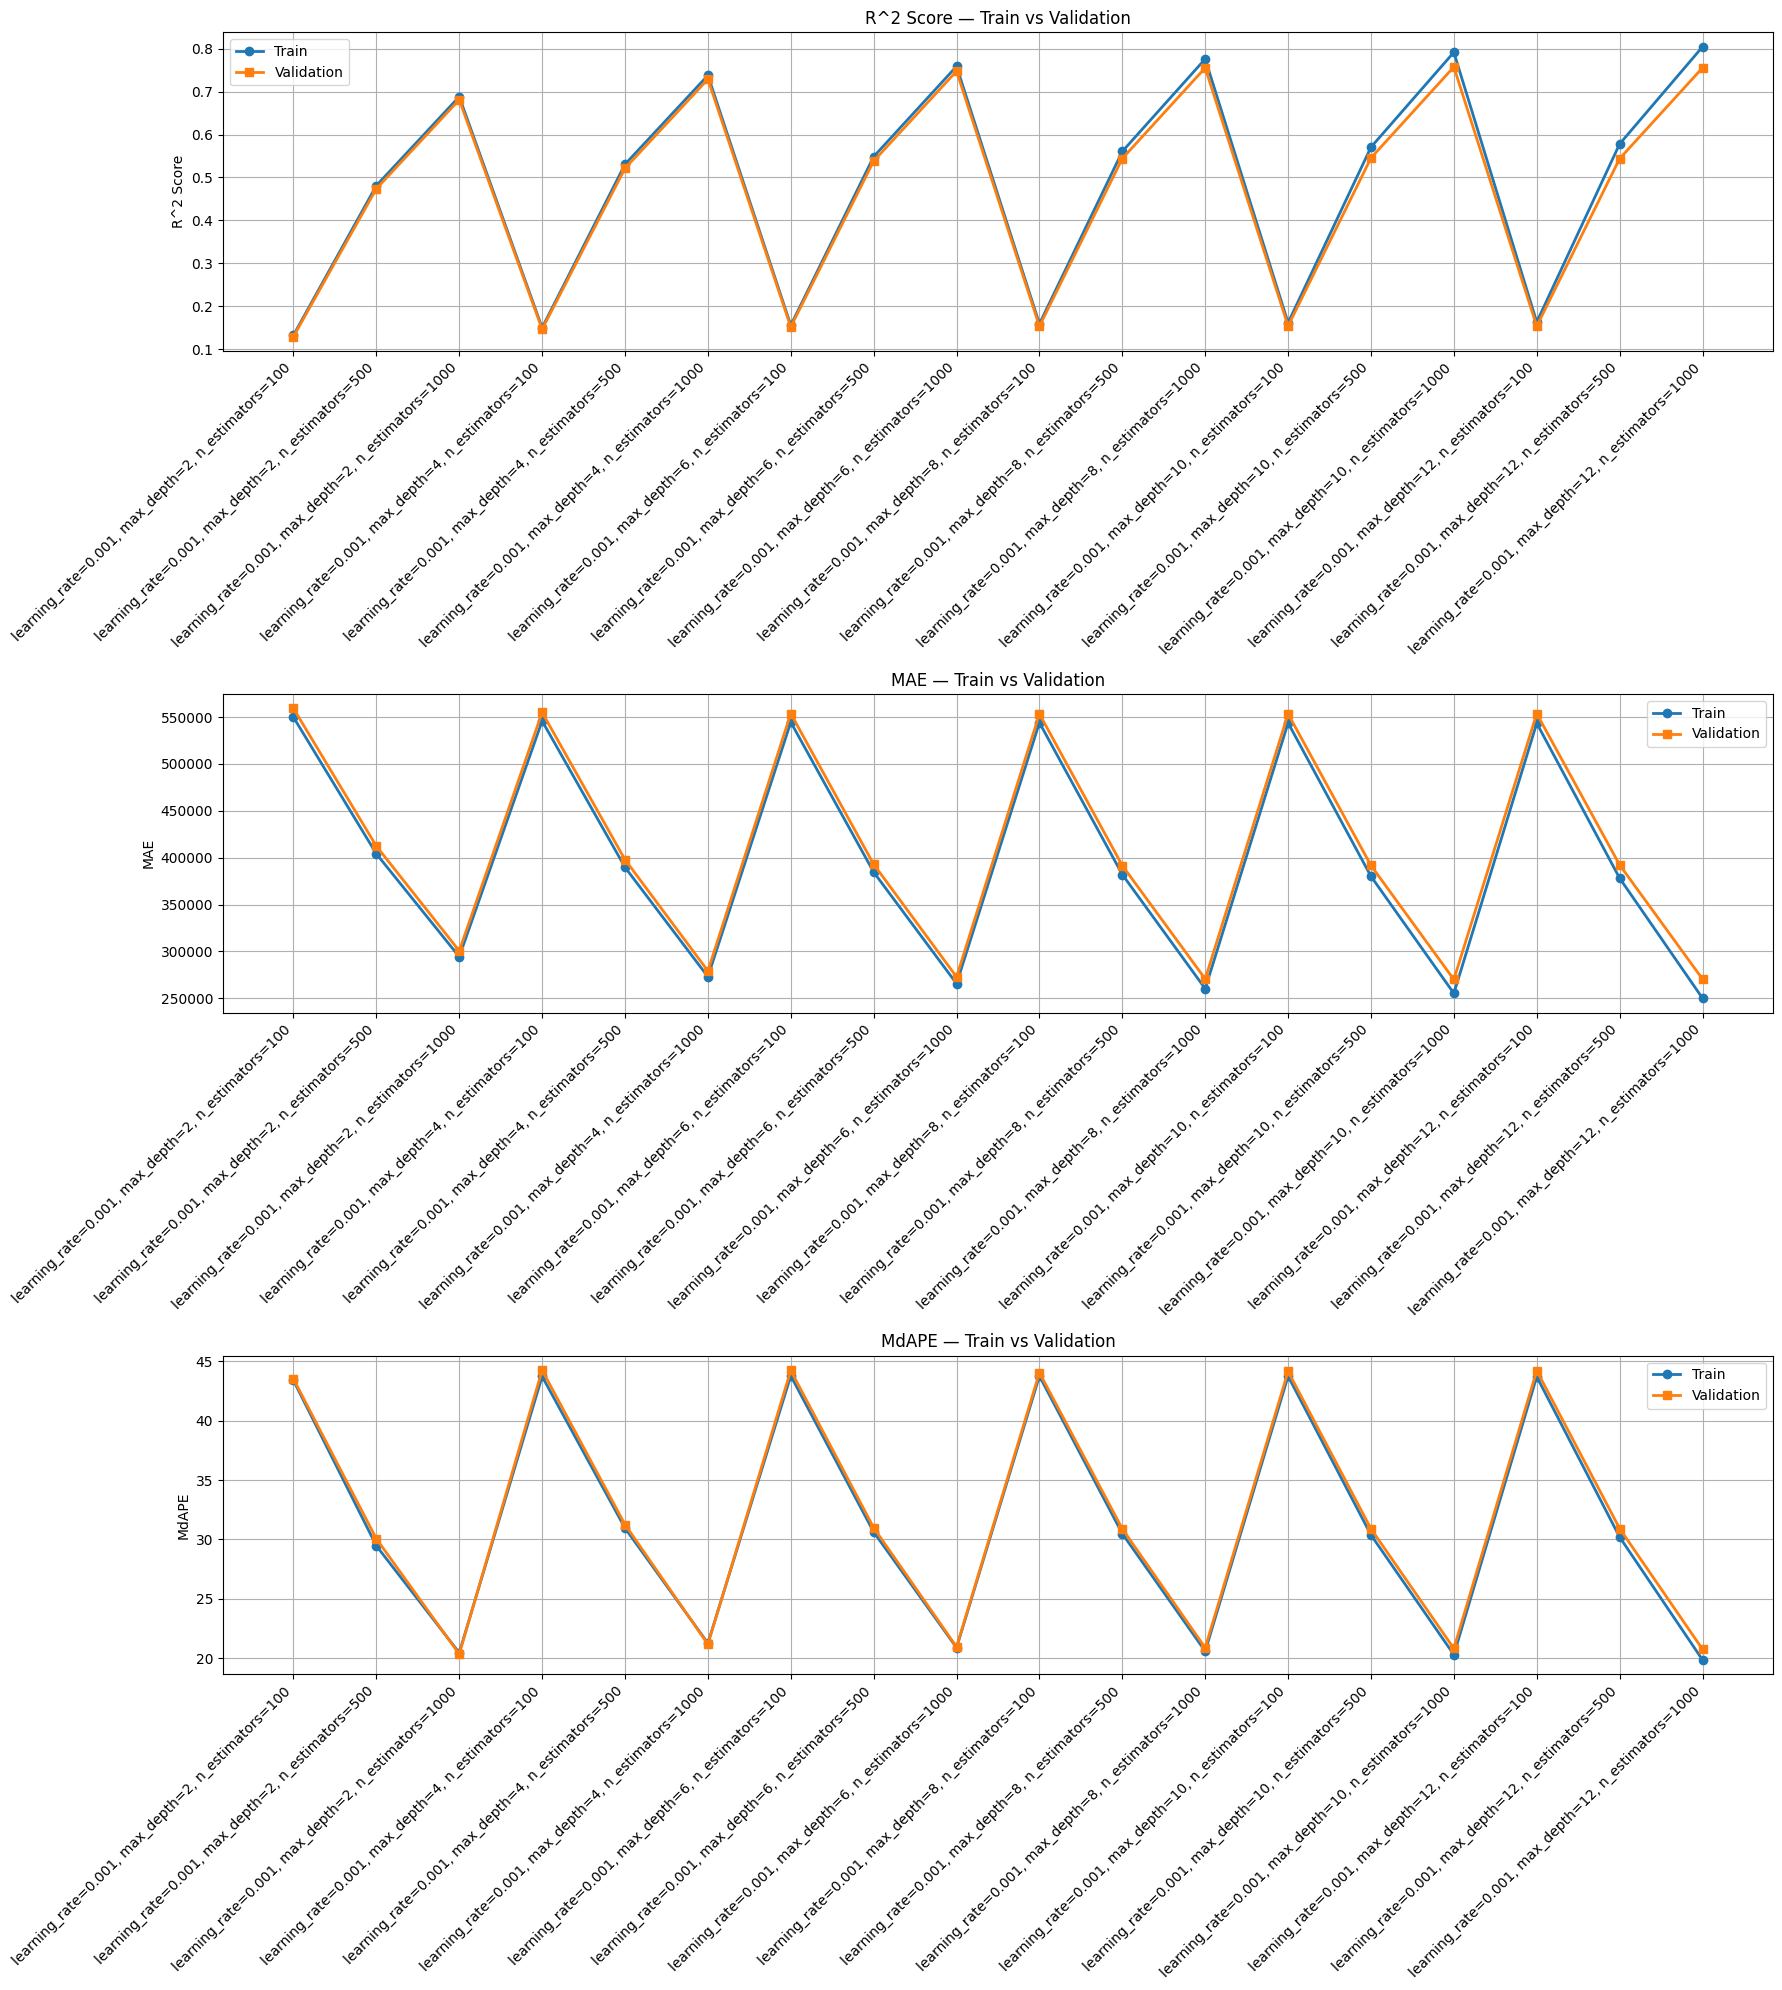

In [12]:
xgb_params = {
    'max_depth': [2, 4, 6, 8, 10, 12],
    'learning_rate': [0.001],
    'n_estimators': [100, 500, 1000]
}

xgb_results = train_xgboost_model(
    df_train_app,
    df_val_app,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.001, 'max_depth': 2, 'n_estimators': 2000}, 'Train R^2': 0.8245031906200176, 'Val R^2': 0.8211482118518796, 'Train RMSE': np.float64(363811.36140317266), 'Val RMSE': np.float64(371685.19085994136), 'Train MAE': 201952.78439742237, 'Val MAE': 203236.79834141498, 'Train MdAPE': np.float64(13.024882713207608), 'Val MdAPE': np.float64(12.798836133613362)}
{'params': {'learning_rate': 0.001, 'max_depth': 2, 'n_estimators': 4000}, 'Train R^2': 0.8748772718727176, 'Val R^2': 0.8757877017783406, 'Train RMSE': np.float64(307191.8909996781), 'Val RMSE': np.float64(309749.71334431216), 'Train MAE': 163191.29987034434, 'Val MAE': 163125.55679828208, 'Train MdAPE': np.float64(9.534327766193956), 'Val MdAPE': np.float64(9.42207558139535)}
{'params': {'learning_rate': 0.001, 'max_depth': 2, 'n_estimators': 6000}, 'Train R^2': 0.8841077075665826, 'Val R^2': 0.8853472030544234, 'Train RMSE': np.float64(295643.89932013076), 'Val RMSE': np.float64(297591.78704371734), 'Trai

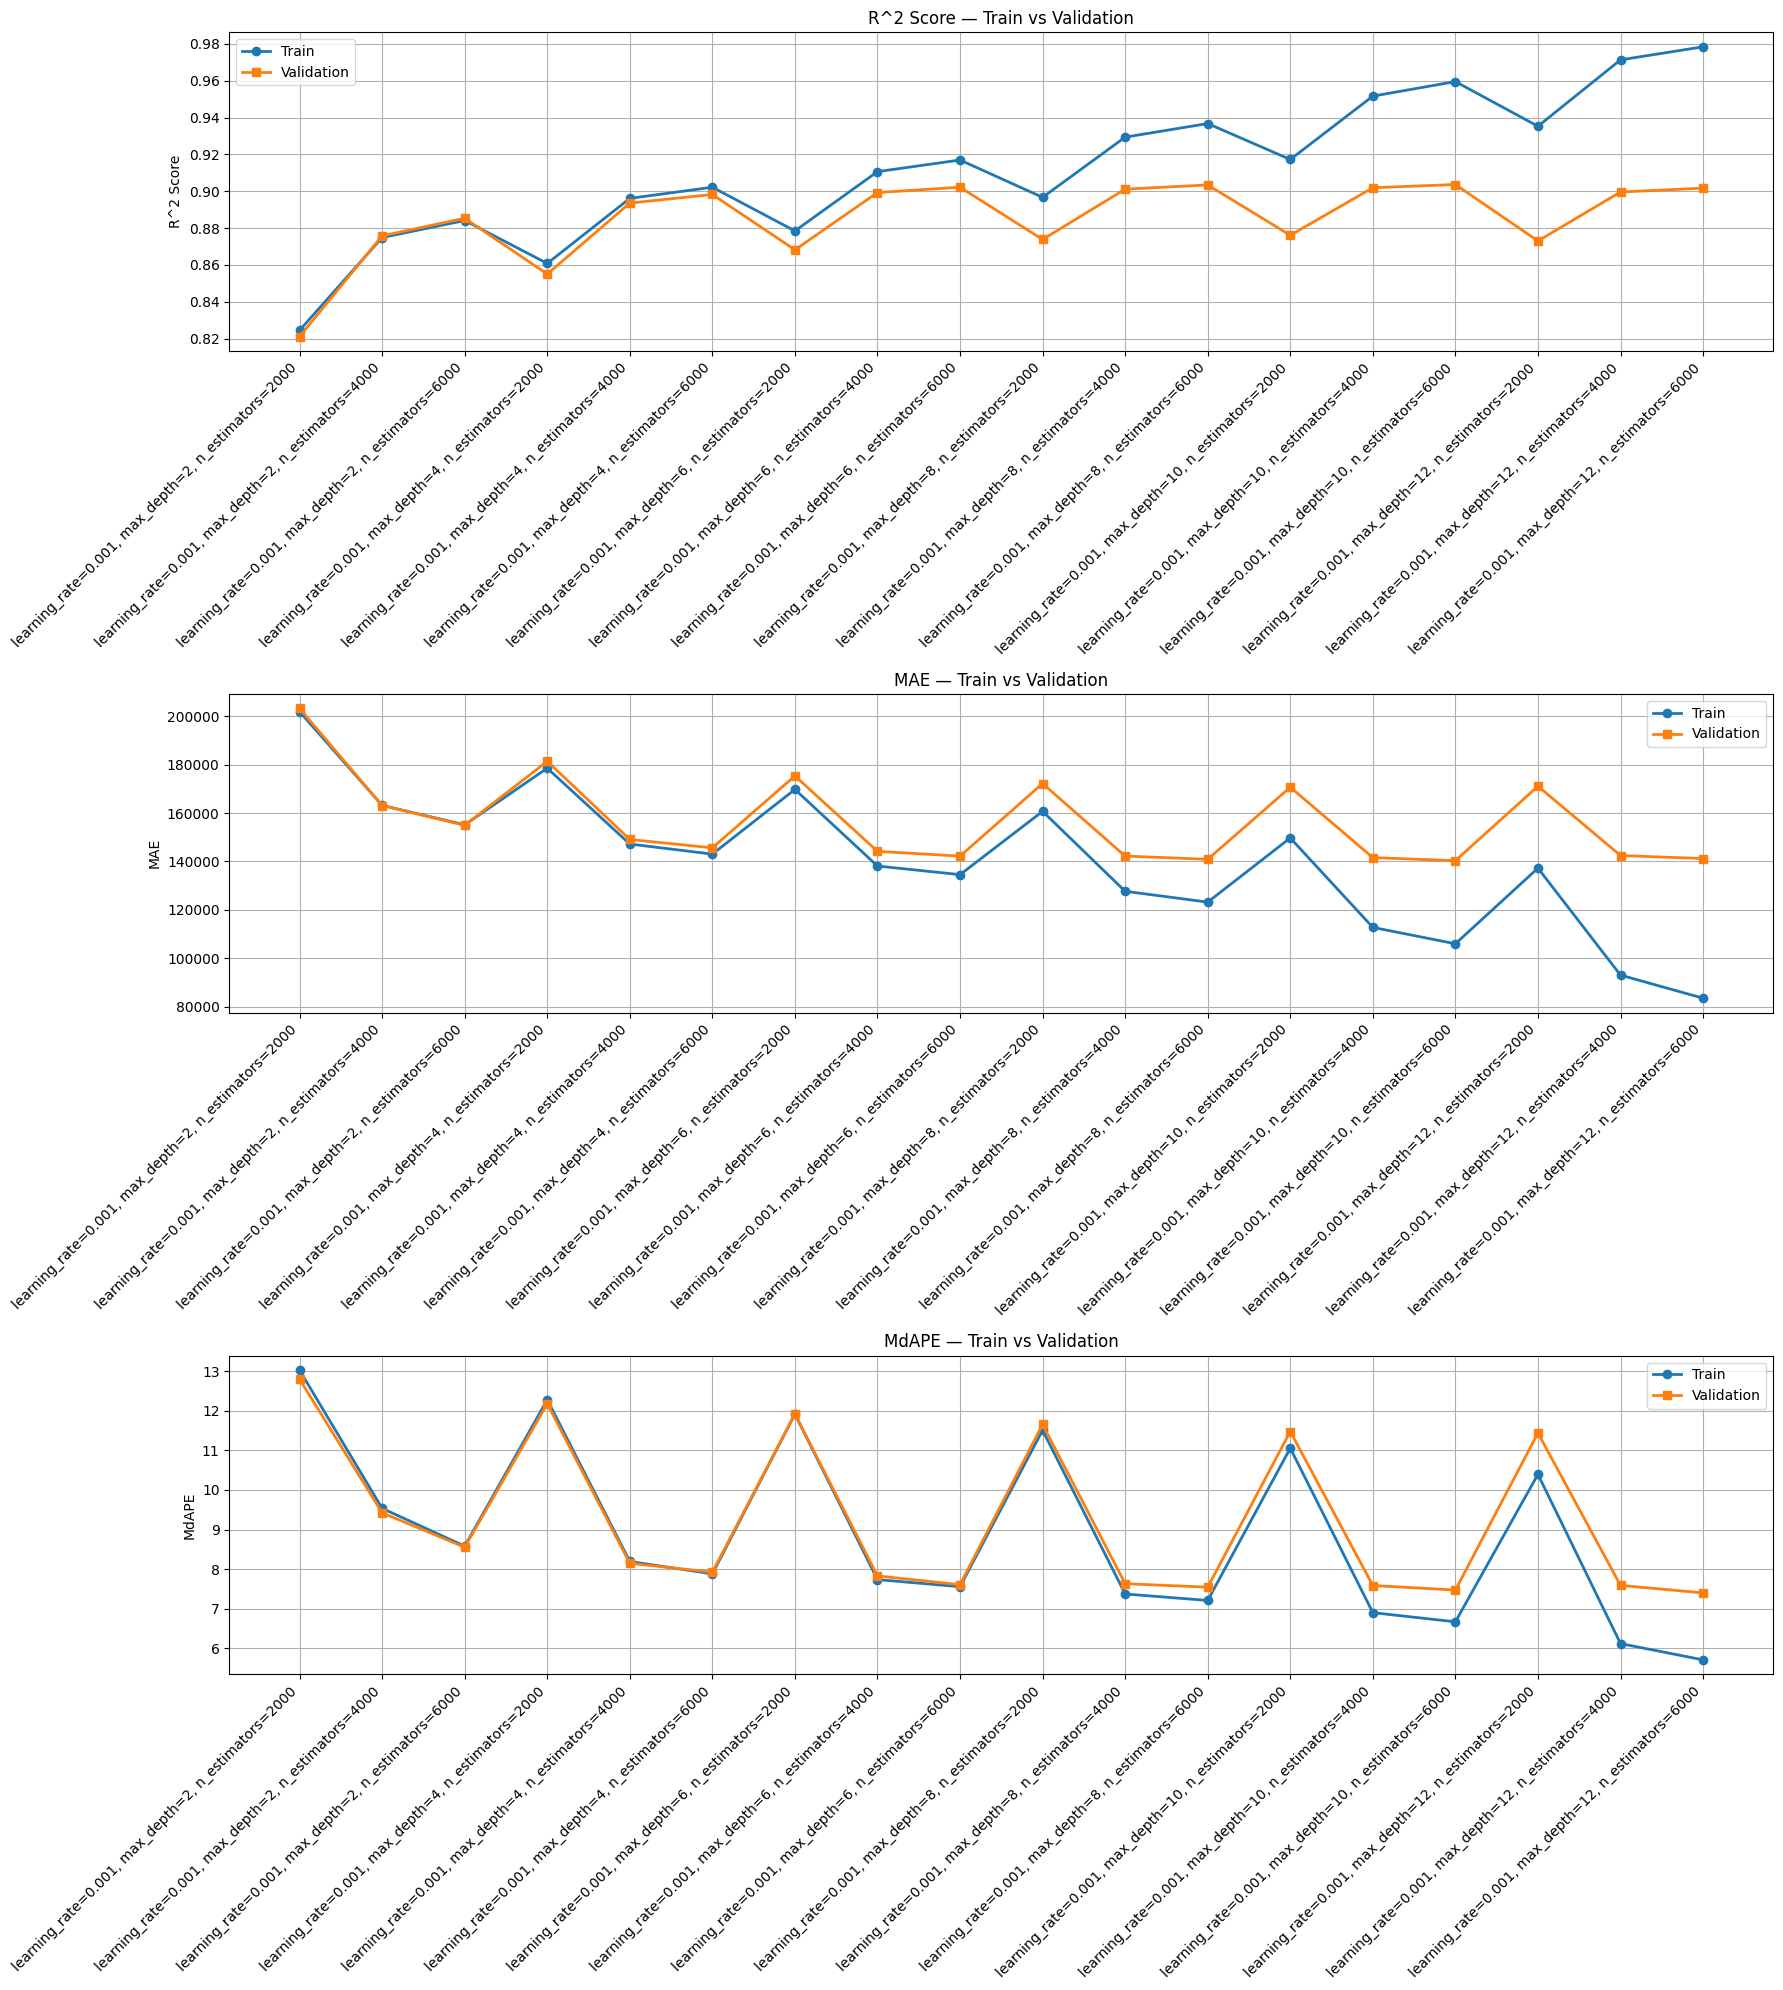

In [15]:
xgb_params = {
    'max_depth': [2, 4, 6, 8, 10, 12],
    'learning_rate': [0.001],
    'n_estimators': [2000, 4000, 6000]
}

xgb_results = train_xgboost_model(
    df_train_app,
    df_val_app,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}, 'Train R^2': 0.6891568208744601, 'Val R^2': 0.6820553195250723, 'Train RMSE': np.float64(484186.0981021586), 'Val RMSE': np.float64(495569.3018524753), 'Train MAE': 293476.88105087134, 'Val MAE': 299736.36409624084, 'Train MdAPE': np.float64(20.375814814814817), 'Val MdAPE': np.float64(20.347631172839506)}
{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 500}, 'Train R^2': 0.880578540069528, 'Val R^2': 0.881875264927333, 'Train RMSE': np.float64(300111.6350366499), 'Val RMSE': np.float64(302064.04805431946), 'Train MAE': 157971.2019914959, 'Val MAE': 157687.06107289647, 'Train MdAPE': np.float64(8.873678405340534), 'Val MdAPE': np.float64(8.815090277777777)}
{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 1000}, 'Train R^2': 0.8921724331530243, 'Val R^2': 0.8931085611206628, 'Train RMSE': np.float64(285171.7807249409), 'Val RMSE': np.float64(287342.63899690047), 'Train MAE': 14

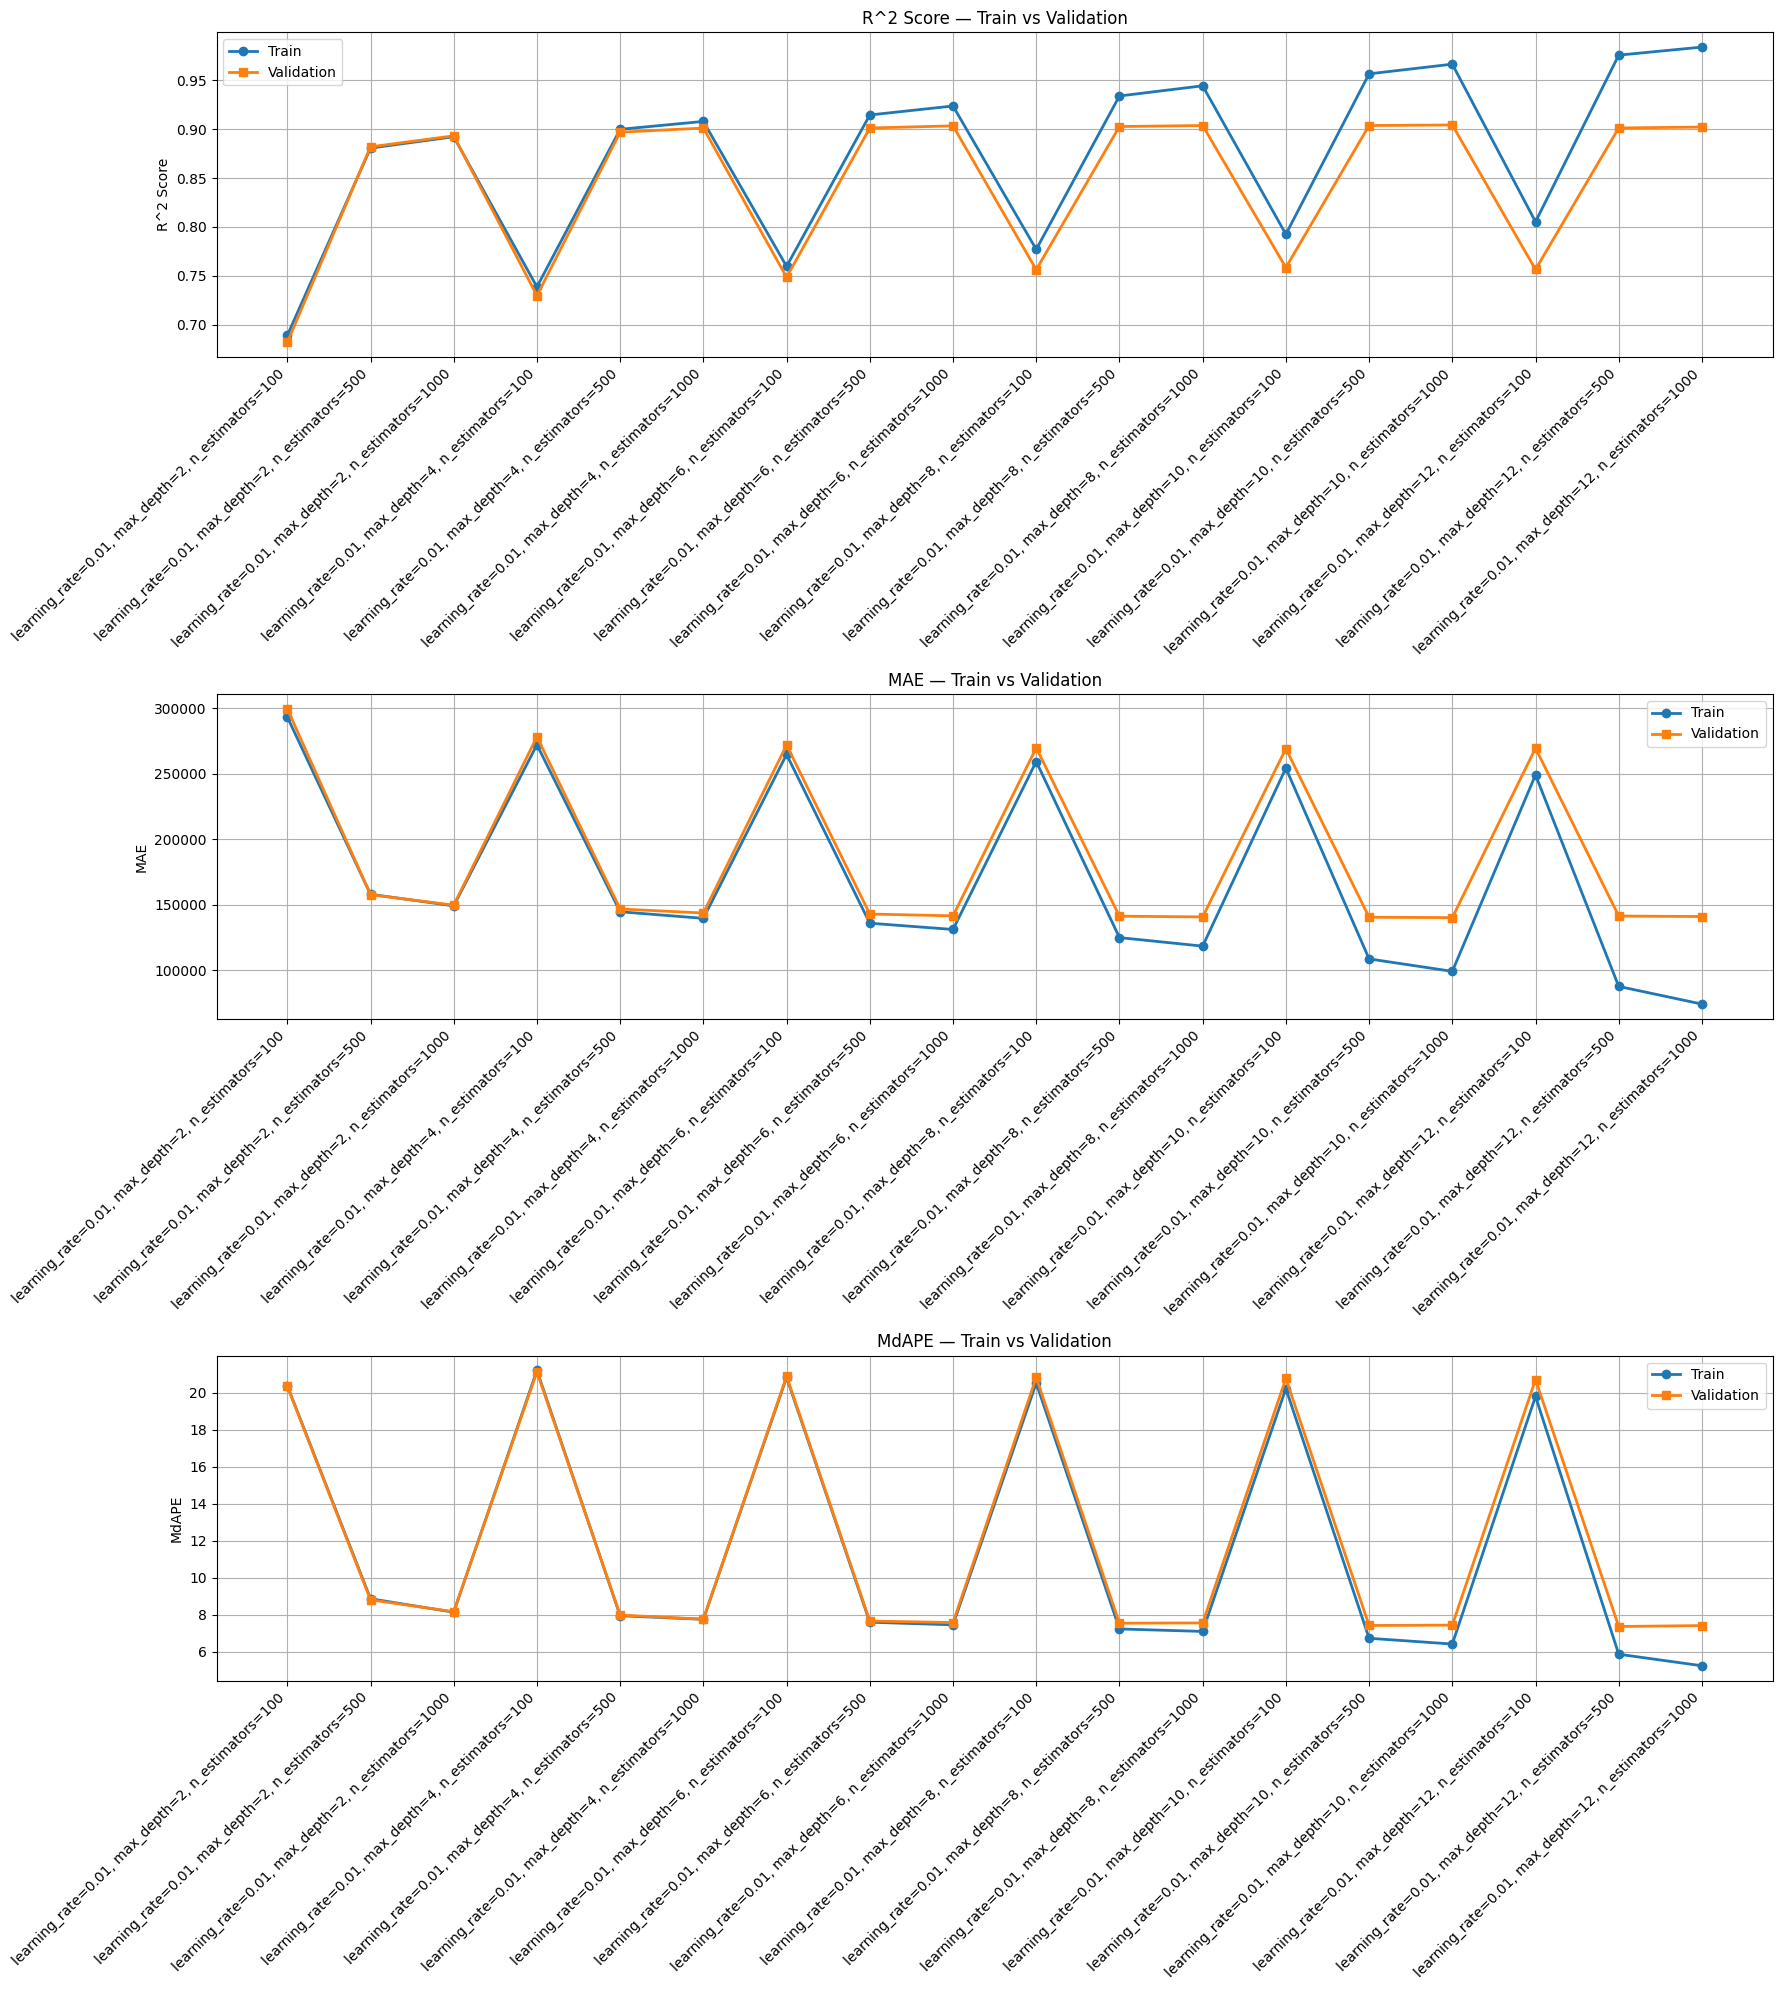

In [13]:
xgb_params = {
    'max_depth': [2, 4, 6, 8, 10, 12],
    'learning_rate': [0.01],
    'n_estimators': [100, 500, 1000]
}

xgb_results = train_xgboost_model(
    df_train_app,
    df_val_app,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 1500}, 'Train R^2': 0.8974843563428553, 'Val R^2': 0.8973044556069821, 'Train RMSE': np.float64(279882.7724724532), 'Val RMSE': np.float64(281646.53666512953), 'Train MAE': 146883.66653449833, 'Val MAE': 147109.20206878637, 'Train MdAPE': np.float64(8.045670667370086), 'Val MdAPE': np.float64(8.093001412429379)}
{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 2000}, 'Train R^2': 0.9001738276175947, 'Val R^2': 0.8992237949013819, 'Train RMSE': np.float64(276187.04636509315), 'Val RMSE': np.float64(279002.1915028864), 'Train MAE': 145139.88818841605, 'Val MAE': 145792.07832432806, 'Train MdAPE': np.float64(7.977498820754716), 'Val MdAPE': np.float64(8.069897119341563)}
{'params': {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 2500}, 'Train R^2': 0.9020209904820486, 'Val R^2': 0.9002842152635443, 'Train RMSE': np.float64(273619.8612332432), 'Val RMSE': np.float64(277530.4054581858), 'Train MAE':

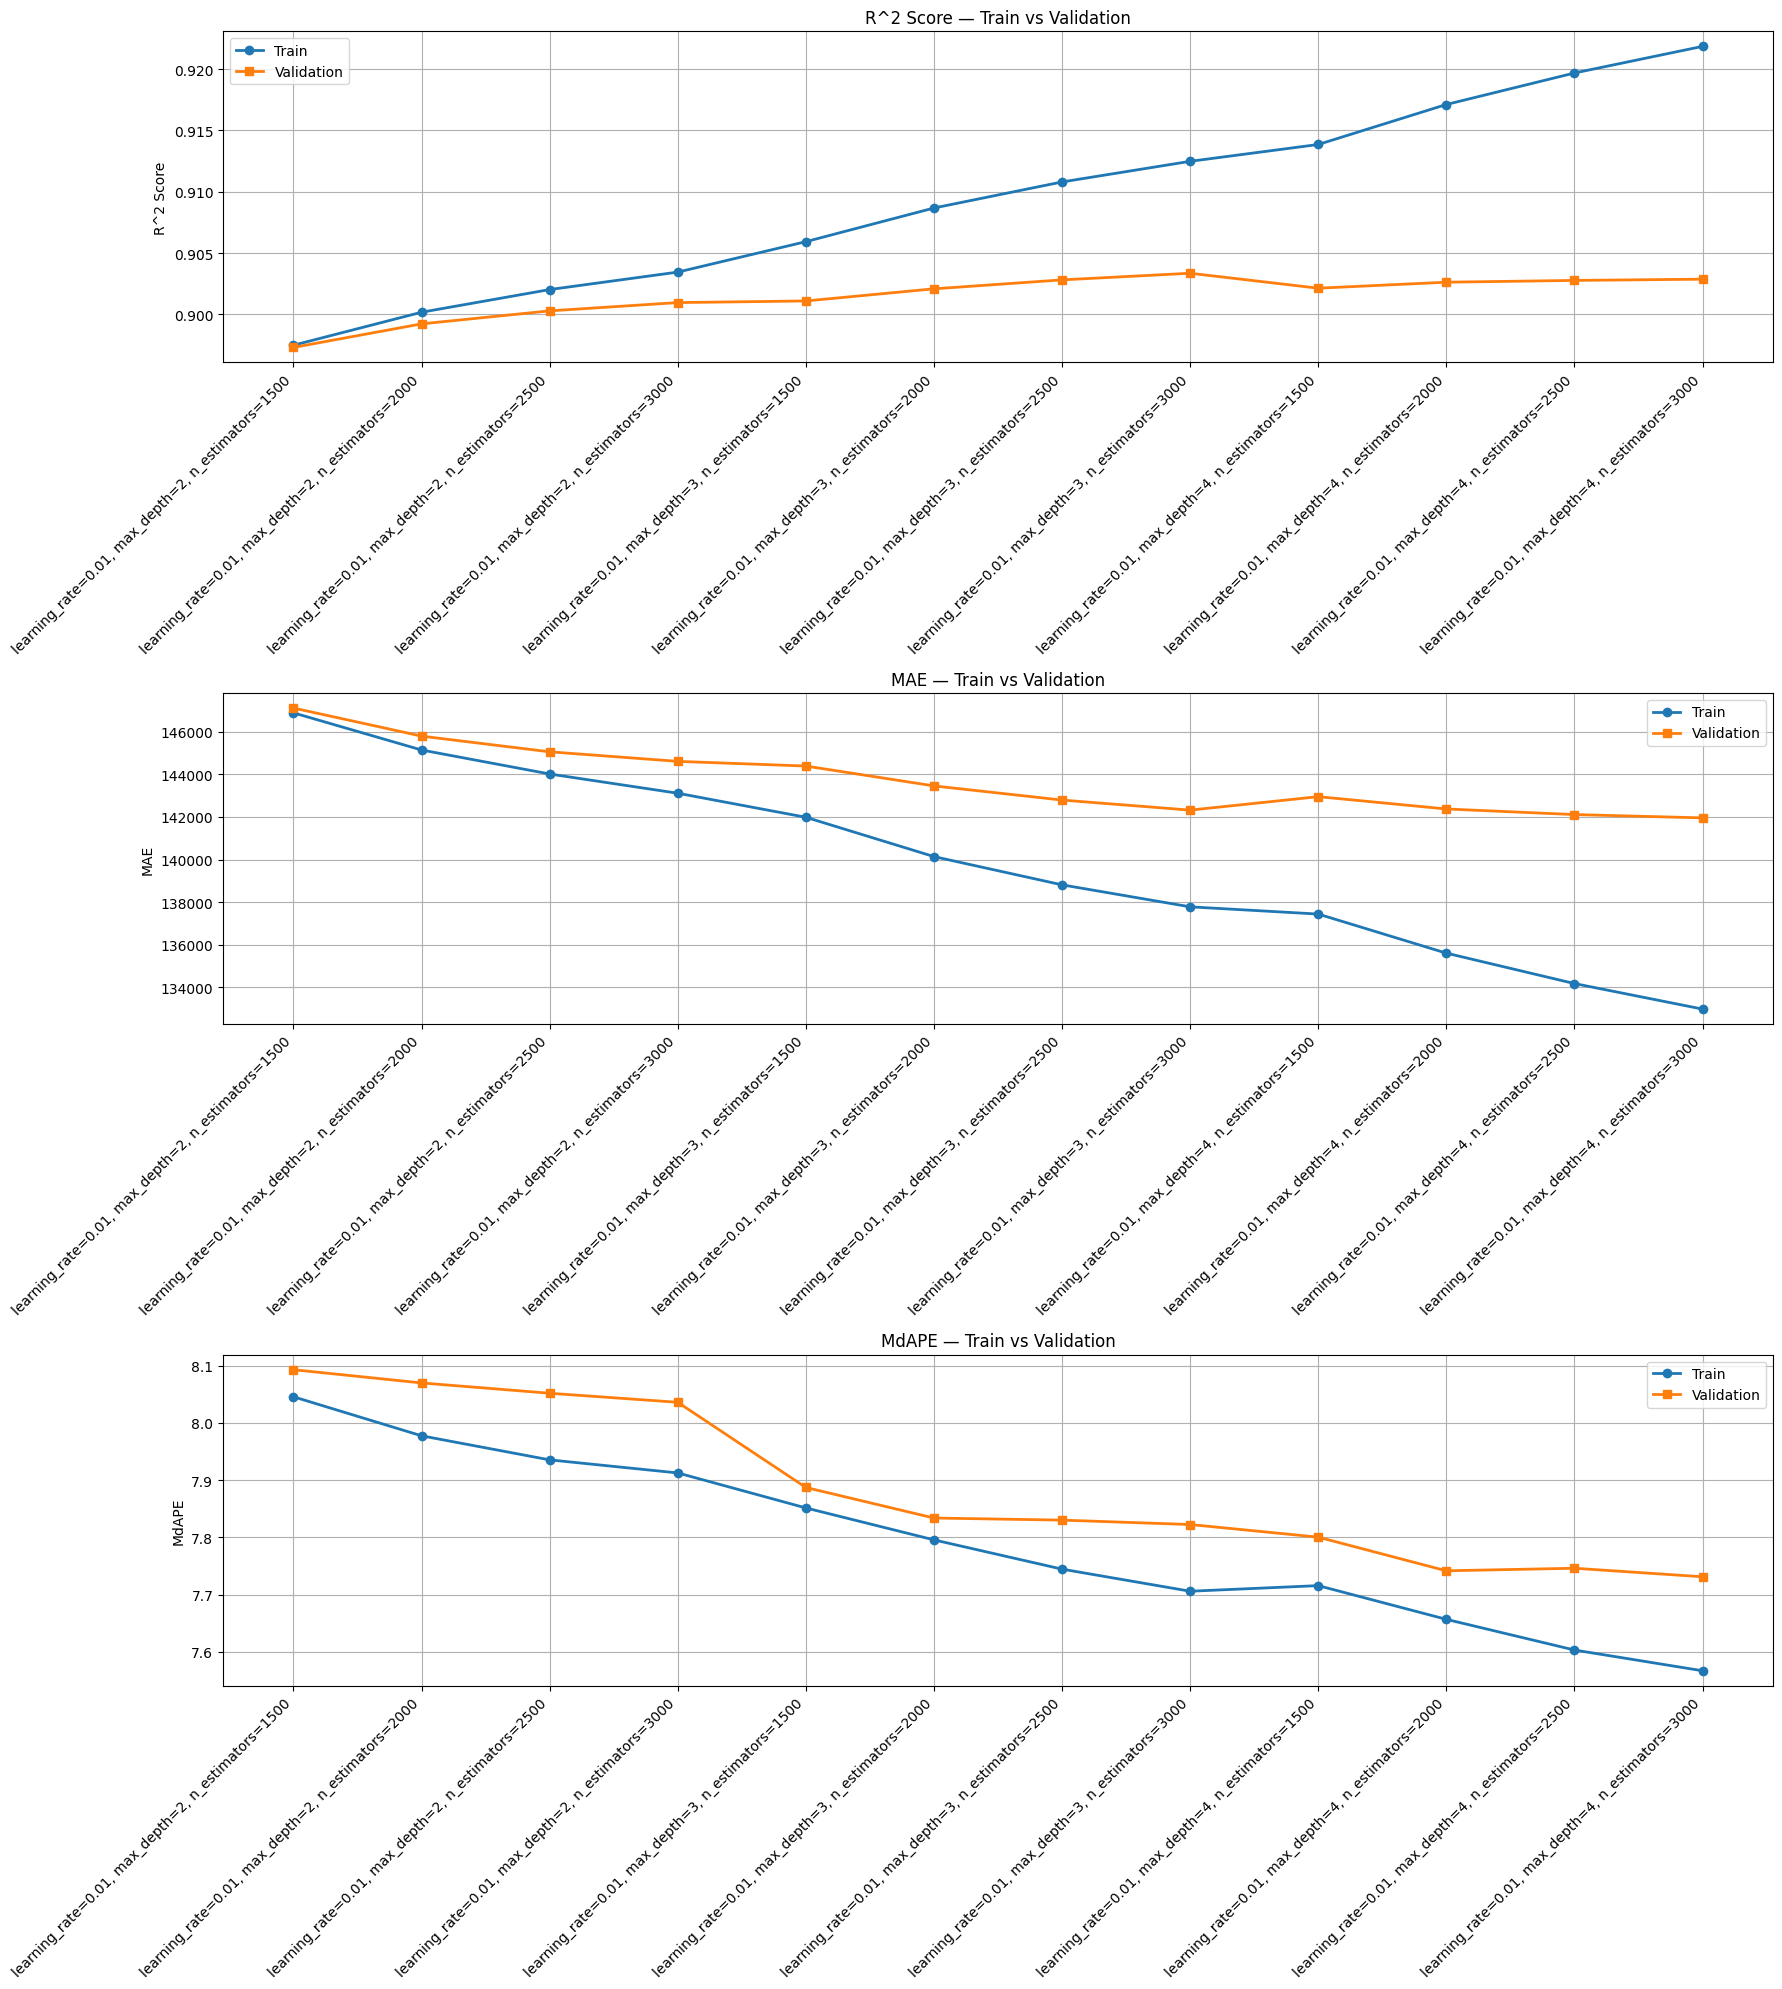

In [12]:
xgb_params = {
    'max_depth': [2, 3, 4],
    'learning_rate': [0.01],
    'n_estimators': [1500, 2000, 2500, 3000]
}

xgb_results = train_xgboost_model(
    df_train_app,
    df_val_app,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

{'params': {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}, 'Train R^2': 0.8910657995687435, 'Val R^2': 0.8923913064615944, 'Train RMSE': np.float64(286631.40328247217), 'Val RMSE': np.float64(288305.079340085), 'Train MAE': 151179.85893956685, 'Val MAE': 151244.8041140205, 'Train MdAPE': np.float64(8.397193999474789), 'Val MdAPE': np.float64(8.30795)}
{'params': {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 500}, 'Train R^2': 0.9052588070434184, 'Val R^2': 0.9025983686880092, 'Train RMSE': np.float64(267307.4539328398), 'Val RMSE': np.float64(274291.10860569344), 'Train MAE': 141162.64273058748, 'Val MAE': 143643.43420401542, 'Train MdAPE': np.float64(7.9501256302981576), 'Val MdAPE': np.float64(7.9647894736842115)}
{'params': {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 1000}, 'Train R^2': 0.9092660078018387, 'Val R^2': 0.9037541318806941, 'Train RMSE': np.float64(261593.32302547438), 'Val RMSE': np.float64(272658.8894768963), 'Train MAE': 138461.523282

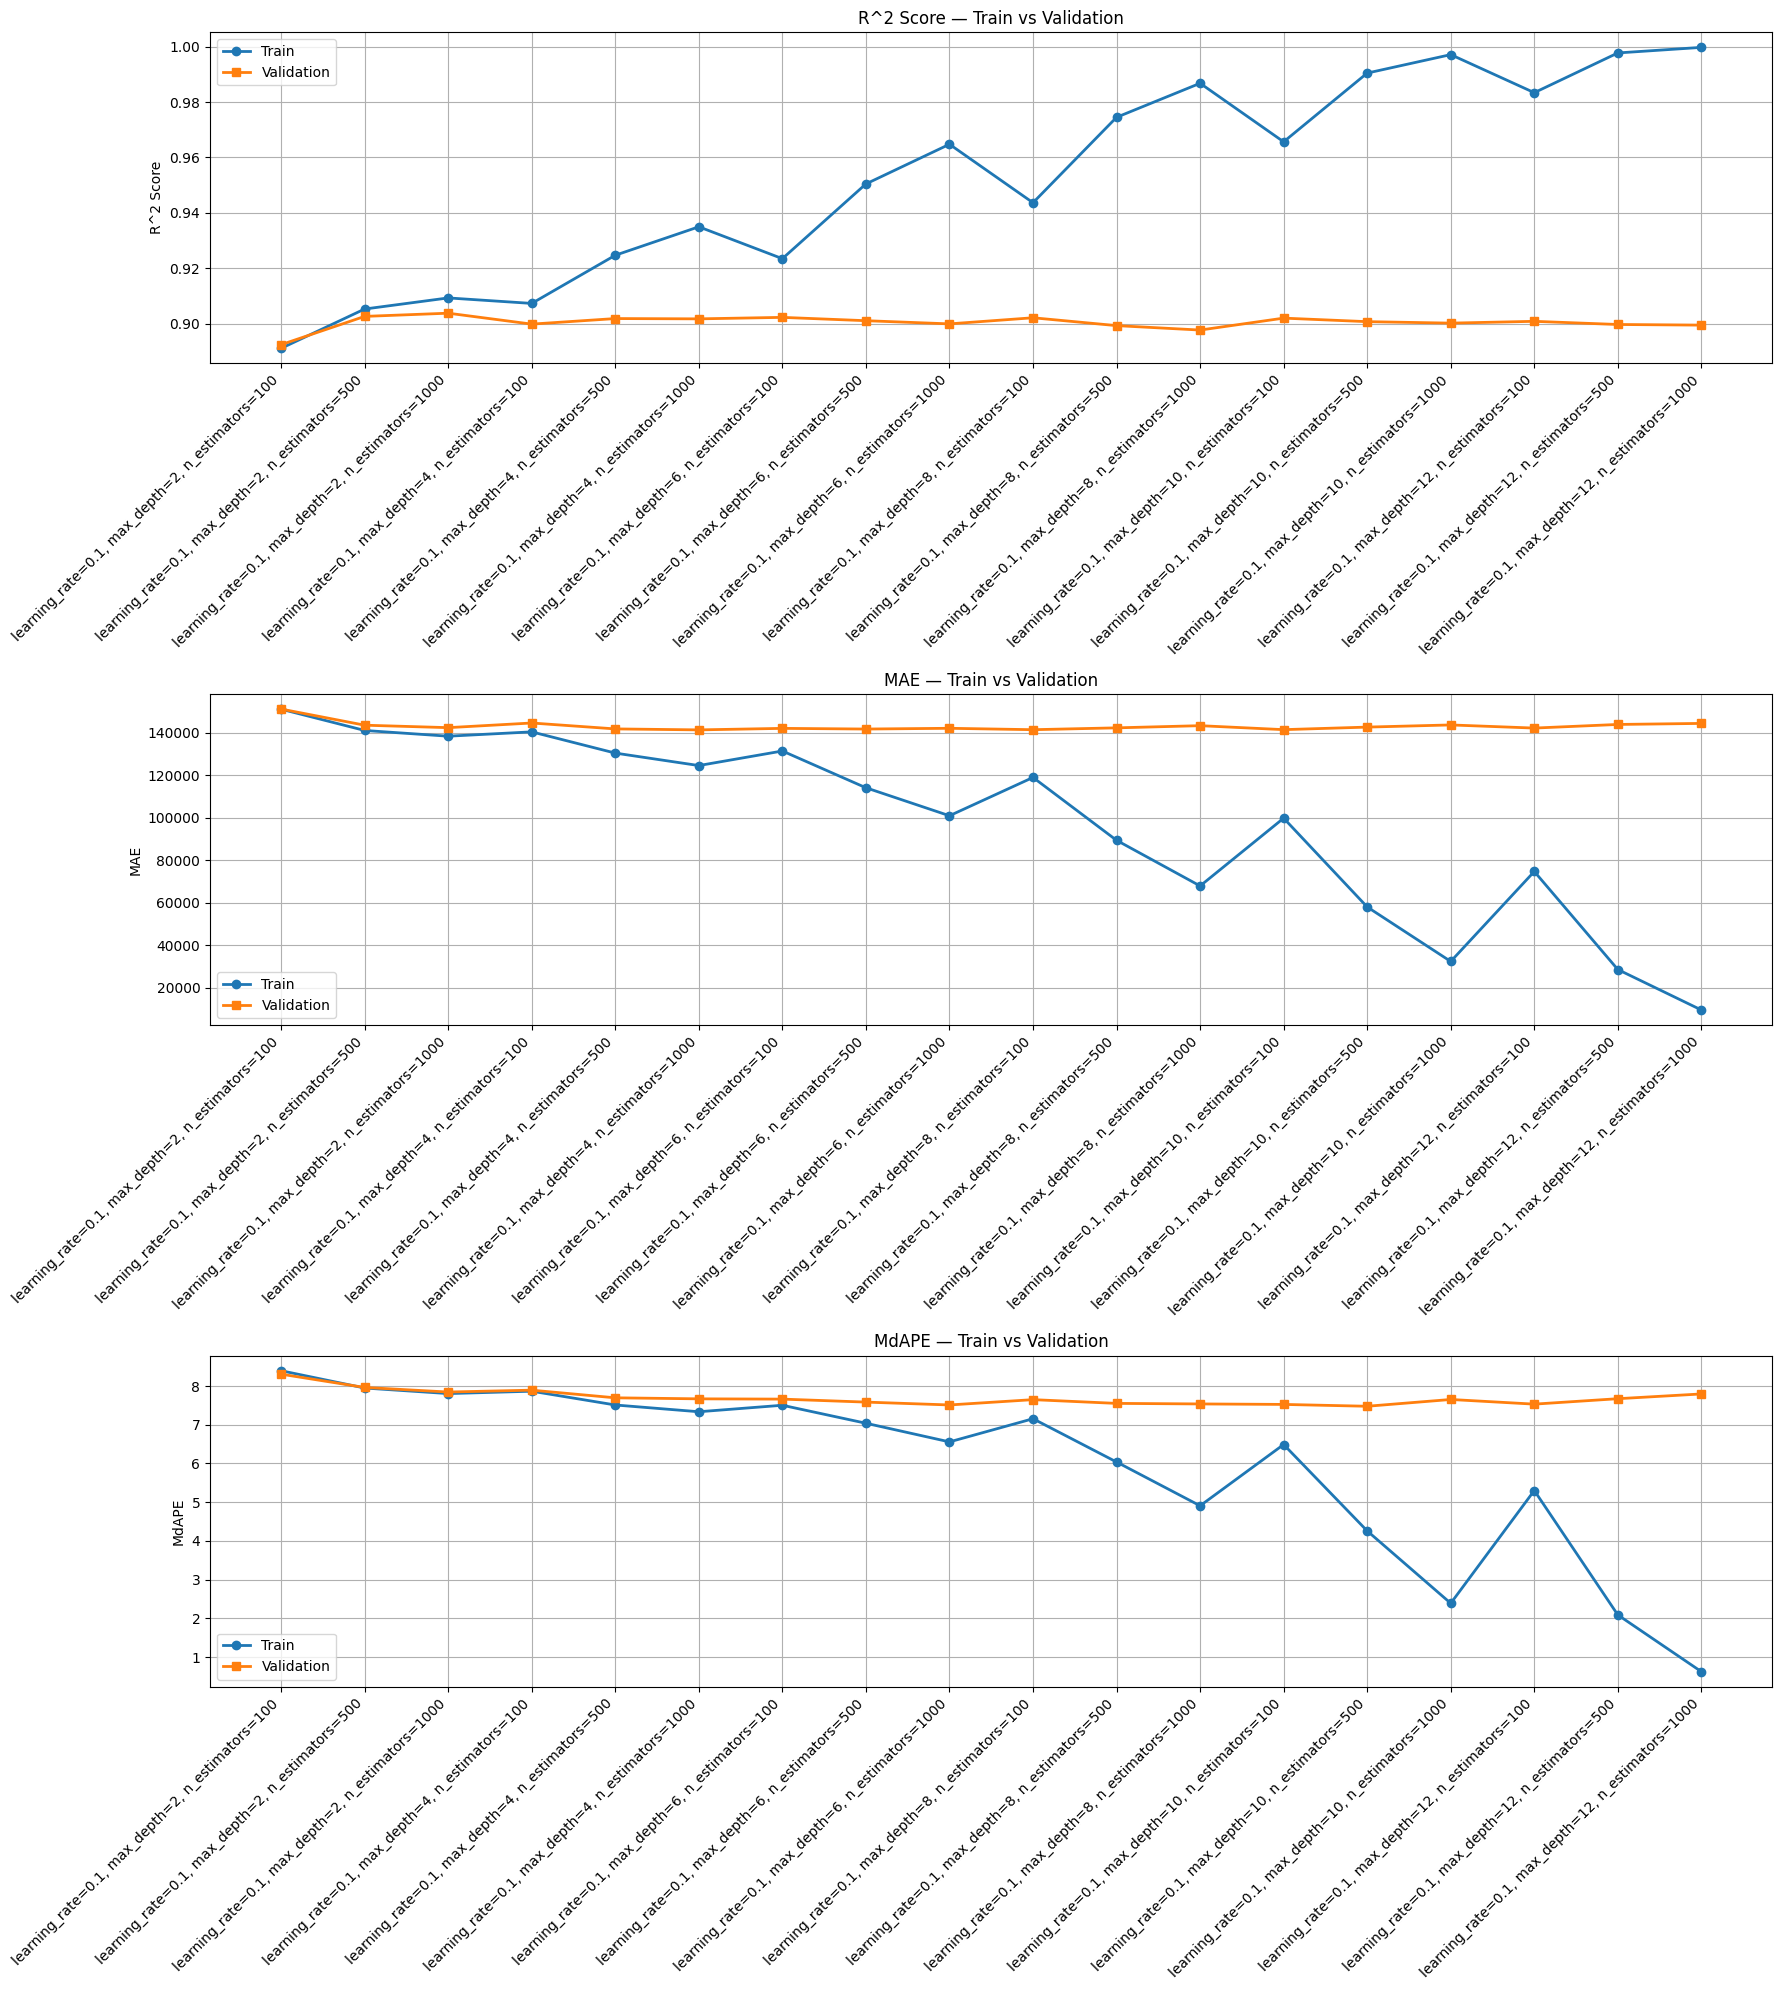

In [14]:
xgb_params = {
    'max_depth': [2, 4, 6, 8, 10, 12],
    'learning_rate': [0.1],
    'n_estimators': [100, 500, 1000]
}

xgb_results = train_xgboost_model(
    df_train_app,
    df_val_app,
    param_grid=xgb_params
)

plot_train_vs_val_metrics(xgb_results)

## Summary of XGBoost for App Feature Set

Several different learning rates, max depths and number of trees showed similar results. Some key results (validation set scores) are given in the table below for comparison.

| Learning Rate | Max Depth | Number of Trees | R-Squared | MAE | MdAPE |
|----------|----------|----------|----------|----------|----------|
| 0.001 | 4 | 3000 |0.9022 | \$142,209 | 7.60% |
| 0.01 | 4 | 1000 | 0.9010 | \$143,672 | 7.69% |
| 0.1 | 2 | 1000 | 0.9038 | \$142,486 | 7.84% |

Next we examine the model with learning rate 0.001, max depth 4 and 3000 trees.

In [20]:
y_train_app = df_train_app["ClosePrice"].copy()
X_train_app = df_train_app.drop(columns=["ClosePrice"]).copy()

y_eval_app = df_val_app["ClosePrice"].copy()
X_eval_app = df_val_app.drop(columns=["ClosePrice"]).copy()

model_app = XGBRegressor(
    random_state=42,
    objective="reg:squarederror",
    learning_rate = 0.001,
    max_depth = 4,
    n_estimators = 3000
)

model_app.fit(X_train_app, y_train_app)

# Predictions
y_pred_train_app = model_app.predict(X_train_app)
y_pred_val_app = model_app.predict(X_eval_app)

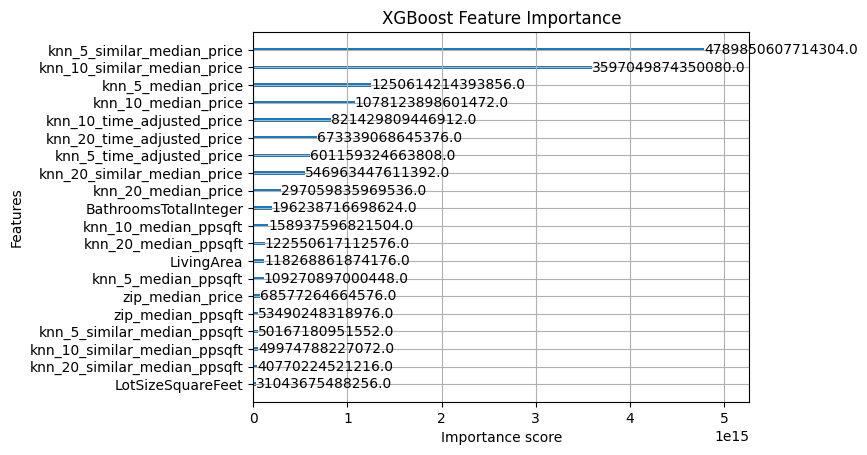

In [21]:
xgb.plot_importance(
    model_app,
    importance_type='gain',
    max_num_features=20
)

plt.title("XGBoost Feature Importance")
plt.show()

In [22]:
importance = model_app.get_booster().get_score(
    importance_type='gain'
)

importance_df = pd.DataFrame(
    importance.items(),
    columns=['Feature', 'Gain']
)

importance_df['Importance (%)'] = (
    importance_df['Gain'] /
    importance_df['Gain'].sum() * 100
)

importance_df = importance_df.sort_values(
    'Importance (%)',
    ascending=False
)

print(importance_df)

                         Feature          Gain  Importance (%)
6     knn_5_similar_median_price  4.789851e+15       32.547313
7    knn_10_similar_median_price  3.597050e+15       24.442162
9             knn_5_median_price  1.250614e+15        8.497996
10           knn_10_median_price  1.078124e+15        7.325914
13    knn_10_time_adjusted_price  8.214298e+14        5.581663
14    knn_20_time_adjusted_price  6.733391e+14        4.575378
12     knn_5_time_adjusted_price  6.011593e+14        4.084912
8    knn_20_similar_median_price  5.469634e+14        3.716648
11           knn_20_median_price  2.970598e+14        2.018539
1          BathroomsTotalInteger  1.962387e+14        1.333453
19          knn_10_median_ppsqft  1.589376e+14        1.079990
20          knn_20_median_ppsqft  1.225506e+14        0.832739
3                     LivingArea  1.182689e+14        0.803644
18           knn_5_median_ppsqft  1.092709e+14        0.742502
21              zip_median_price  6.857726e+13        0

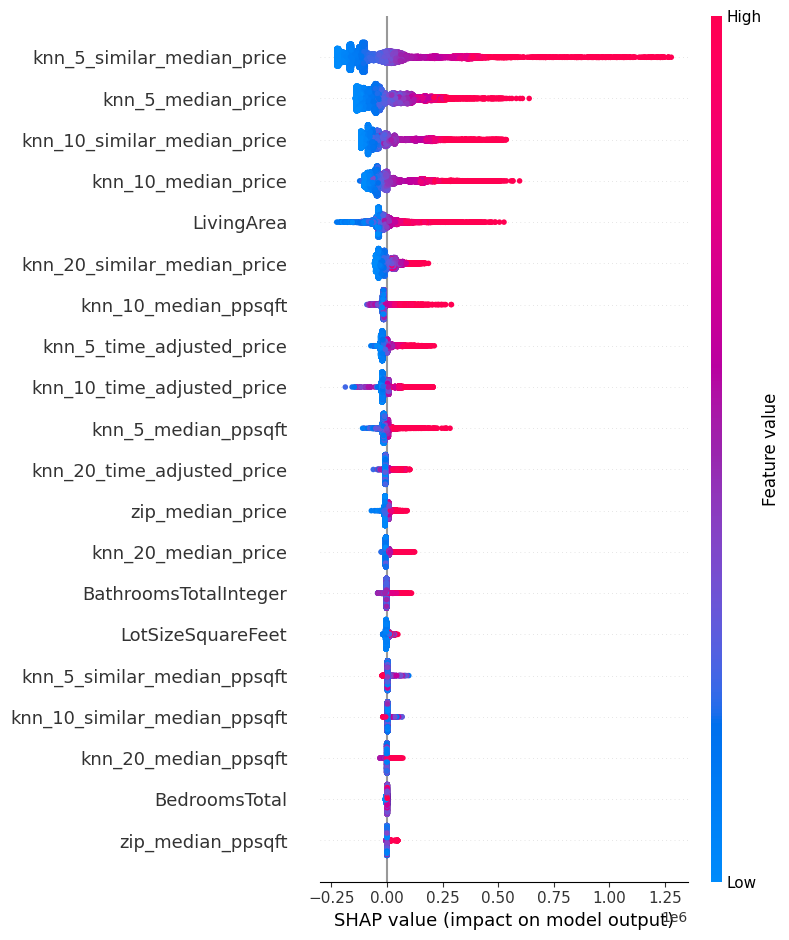

In [23]:
explainer = shap.TreeExplainer(model_app)
shap_values = explainer.shap_values(X_eval_app)

shap.summary_plot(shap_values, X_eval_app)

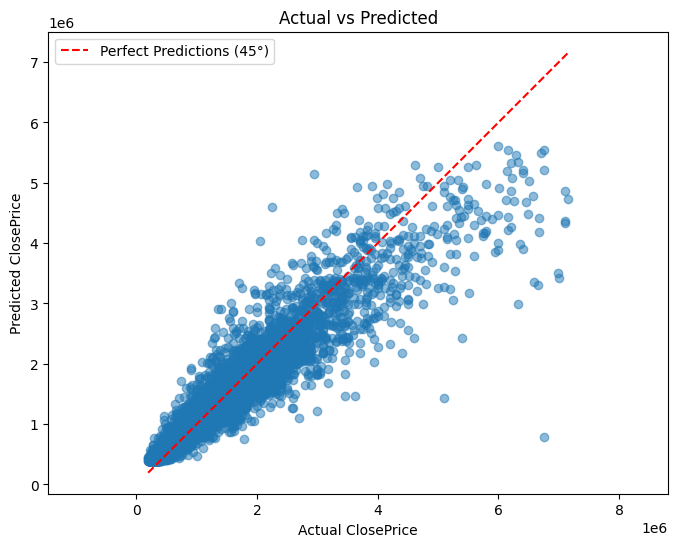

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(y_eval_app, y_pred_val_app, alpha=0.5)

# Add 45-degree reference line
min_val = min(y_eval_app.min(), y_pred_val_app.min())
max_val = max(y_eval_app.max(), y_pred_val_app.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    label='Perfect Predictions (45°)'
)

plt.xlabel('Actual ClosePrice')
plt.ylabel('Predicted ClosePrice')
plt.title('Actual vs Predicted')

plt.legend()
plt.axis('equal')
plt.show()